In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 78.6 MB/s eta 0:00:00


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

In [4]:
import pandas as pd

# 1. CSV 파일 로드 (cp949 인코딩이 보통 맞음)
csv_path = "/content/drive/MyDrive/final_proj/망원동_영역_매출_결합.csv"
df = pd.read_csv(csv_path, encoding="utf-8")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 474 entries, 0 to 473
Data columns (total 62 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   상권_구분_코드         474 non-null    object
 1   상권_구분_코드_명       474 non-null    object
 2   상권_코드            474 non-null    int64 
 3   상권_코드_명          474 non-null    object
 4   엑스좌표_값           474 non-null    int64 
 5   와이좌표_값           474 non-null    int64 
 6   자치구_코드           474 non-null    int64 
 7   자치구_코드_명         474 non-null    object
 8   행정동_코드           474 non-null    int64 
 9   행정동_코드_명         474 non-null    object
 10  영역_면적            474 non-null    int64 
 11  기준_년분기_코드        474 non-null    int64 
 12  서비스_업종_코드        474 non-null    object
 13  서비스_업종_코드_명      474 non-null    object
 14  당월_매출_금액         474 non-null    int64 
 15  당월_매출_건수         474 non-null    int64 
 16  주중_매출_금액         474 non-null    int64 
 17  주말_매출_금액         474 non-null    in

In [18]:
# 서비스_업종_코드_명 컬럼의 고유 값 나열
service_types = df["서비스_업종_코드_명"].dropna().unique()

print("업종 개수:", len(service_types))
service_types

업종 개수: 50


array(['전자상거래업', '조명용품', '화장품', '의약품', '편의점', '슈퍼마켓', '노래방', '네일숍', '미용실',
       '스포츠클럽', '일반의원', '예술학원', '일반교습학원', '커피-음료', '호프-간이주점', '패스트푸드점',
       '중식음식점', '한식음식점', '제과점', '피부관리실', '인테리어', '애완동물', '화초', '문구', '서적',
       '안경', '신발', '일반의류', '반찬가게', '청과상', '육류판매', '가전제품수리', '세탁소',
       '자동차수리', '당구장', '한의원', '치과의원', '스포츠 강습', '분식전문점', '치킨전문점', '양식음식점',
       '일식음식점', '컴퓨터및주변장치판매', '자전거 및 기타운송장비', 'PC방', '가구', '의료기기', '섬유제품',
       '수산물판매', '미곡판매'], dtype=object)

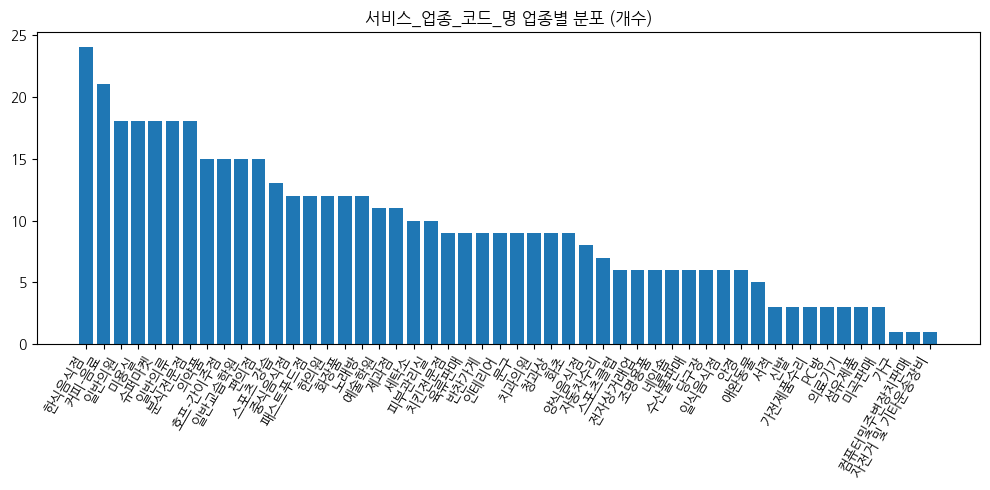

In [19]:
import koreanize_matplotlib

# 한글 폰트 설정
koreanize_matplotlib.koreanize()

# 업종별 개수(빈도)
industry_dist = (
    df["서비스_업종_코드_명"]
    .value_counts(dropna=False)
    .reset_index()
)

industry_dist.columns = ["서비스_업종_코드_명", "개수"]

industry_dist

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(industry_dist["서비스_업종_코드_명"], industry_dist["개수"])
plt.xticks(rotation=60, ha="right")
plt.title("서비스_업종_코드_명 업종별 분포 (개수)")
plt.tight_layout()
plt.show()



In [20]:
grouped_xy = df.groupby(
    ["엑스좌표_값", "와이좌표_값"]
)

# 그룹 개수 확인
grouped_xy.ngroups


8

In [24]:
xy_count = (
    df.groupby(["엑스좌표_값", "와이좌표_값"])
      .size()
      .reset_index(name="개수")
)

xy_count.head(8)


,엑스좌표_값,와이좌표_값,개수
0,191170,450546,10
1,191287,450928,60
2,191345,451292,54
3,191619,450607,121
4,191644,450958,53
5,191646,451113,48
6,191763,450761,45
7,192088,450652,83


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

target_industries = [
    '애완동물','화장품','일반의류','반찬가게','청과상','육류판매','편의점','슈퍼마켓',
    '사진관','노래방','세탁소','피부관리실','네일숍','미용실','스포츠클럽','복권방',
    '기타 오락장','PC방','당구장','한의원','일반교습학원','커피-음료','호프-간이주점',
    '분식전문점','치킨전문점','패스트푸드점','제과점','양식음식점','일식음식점',
    '중식음식점','한식음식점','화초','완구','문구','유아의류','수산물판매','독서실',
    '동물병원','골프연습장'
]

df_filt = df[df["서비스_업종_코드_명"].isin(target_industries)].copy()


In [6]:
grouped = (
    df_filt
    .groupby(
        ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"],
        as_index=False
    )
    .agg(
        남성매출=("남성_매출_금액", "sum"),
        여성매출=("여성_매출_금액", "sum")
    )
)

grouped.head()


,기준_년분기_코드,서비스_업종_코드_명,상권_코드_명,남성매출,여성매출
0,20251,PC방,KB국민은행 망원동지점,90557082,22434568
1,20251,네일숍,KB국민은행 망원동지점,0,488423
2,20251,네일숍,마포구청역 7번,1086005,7809161
3,20251,노래방,KB국민은행 망원동지점,71034162,7447593
4,20251,노래방,마포구청역 7번,47591015,4908182


In [12]:
import numpy as np
import matplotlib.pyplot as plt

def plot_gender_sales_side_by_side(industry_name):
    sub = grouped[grouped["서비스_업종_코드_명"] == industry_name].copy()
    sub["기준_년분기_코드"] = sub["기준_년분기_코드"].astype(str)

    quarters = sorted(sub["기준_년분기_코드"].unique())
    areas = sub["상권_코드_명"].unique()

    x = np.arange(len(quarters))
    bar_width = 0.35

    plt.figure(figsize=(12, 6))

    for i, area in enumerate(areas):
        area_df = sub[sub["상권_코드_명"] == area]

        male_vals = [
            area_df.loc[area_df["기준_년분기_코드"] == q, "남성매출"].sum()
            for q in quarters
        ]
        female_vals = [
            area_df.loc[area_df["기준_년분기_코드"] == q, "여성매출"].sum()
            for q in quarters
        ]

        # 남성 바 (왼쪽)
        plt.bar(
            x - bar_width/2,
            male_vals,
            width=bar_width,
            alpha=0.7,
            label=f"{area} (남성)"
        )

        # 여성 바 (오른쪽)
        plt.bar(
            x + bar_width/2,
            female_vals,
            width=bar_width,
            alpha=0.7,
            label=f"{area} (여성)"
        )

    plt.xticks(x, quarters)
    plt.xlabel("기준_년분기_코드")
    plt.ylabel("매출 금액")
    plt.title(f"{industry_name} | 분기별 남성 vs 여성 매출 (상권별)")
    plt.legend()
    plt.tight_layout()
    plt.show()


# 분기/상권별 남녀 매출 금액

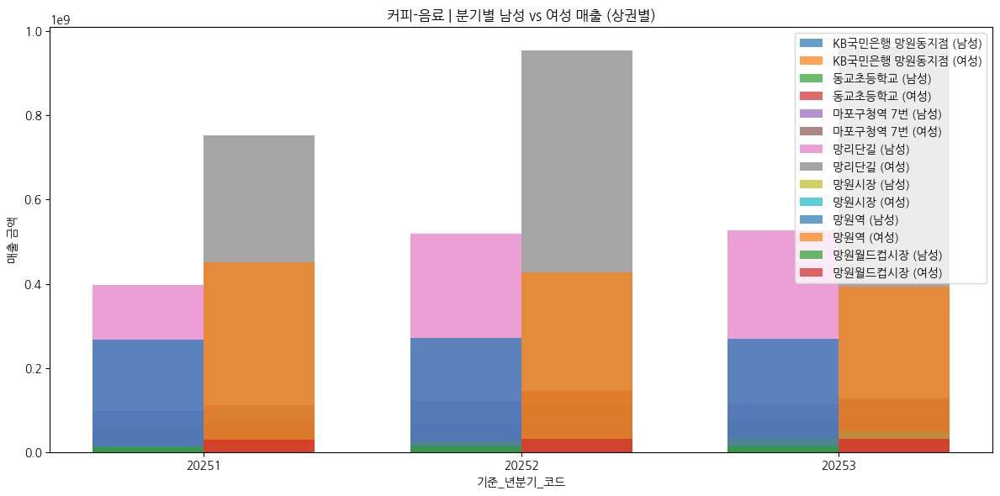

In [13]:
plot_gender_sales_side_by_side("커피-음료")


📊 업종: 애완동물


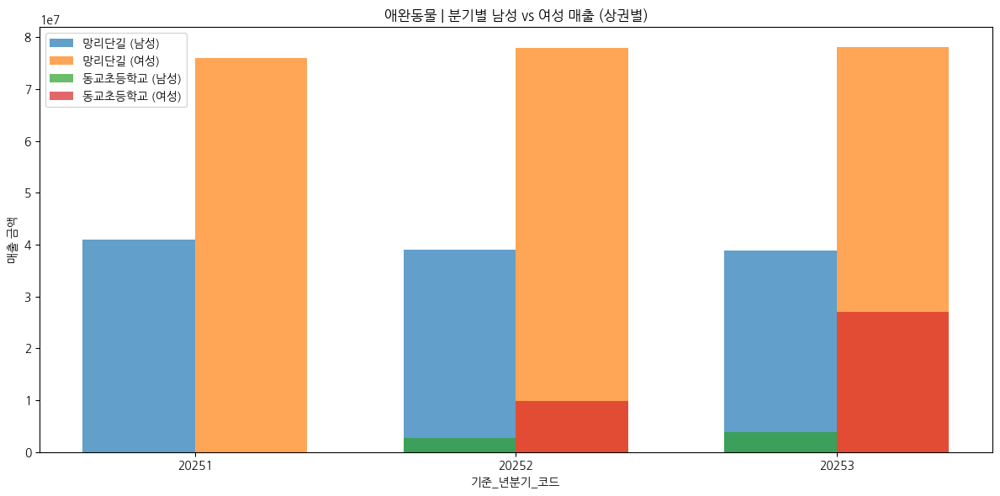

📊 업종: 화장품


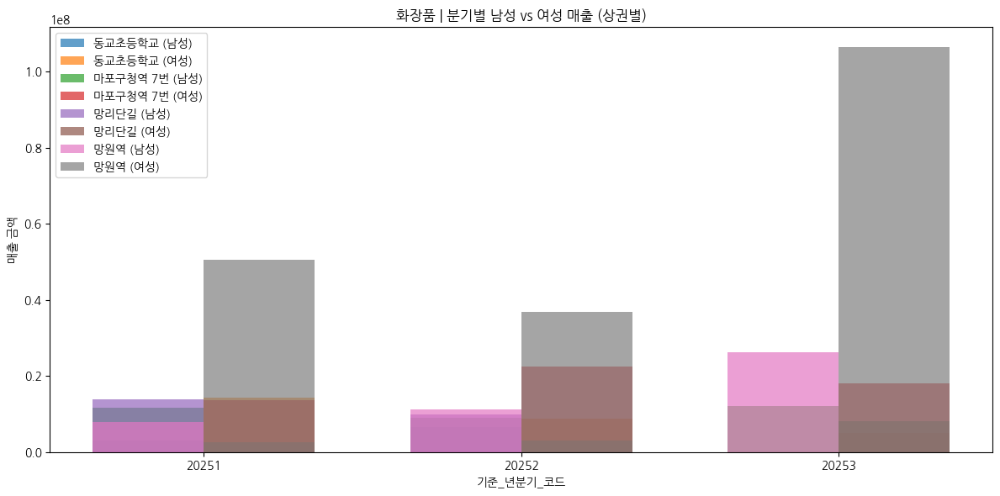

📊 업종: 일반의류


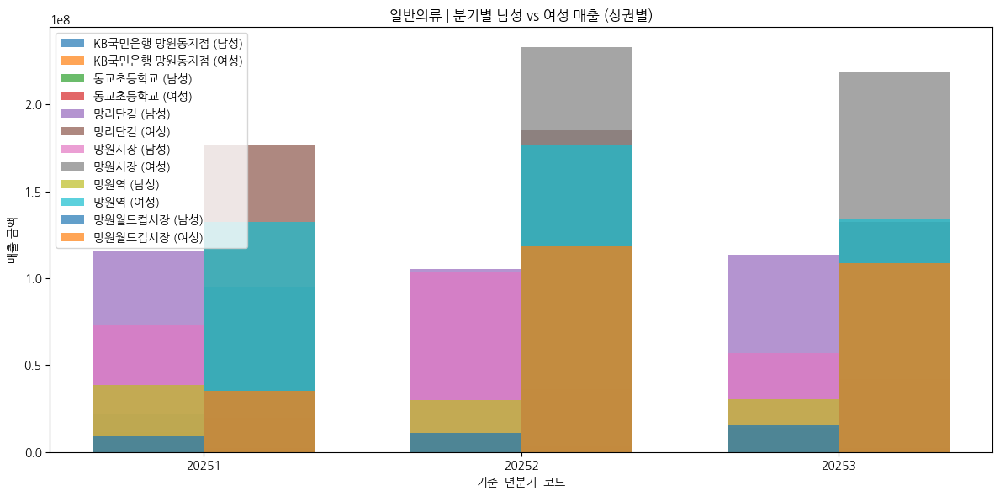

📊 업종: 반찬가게


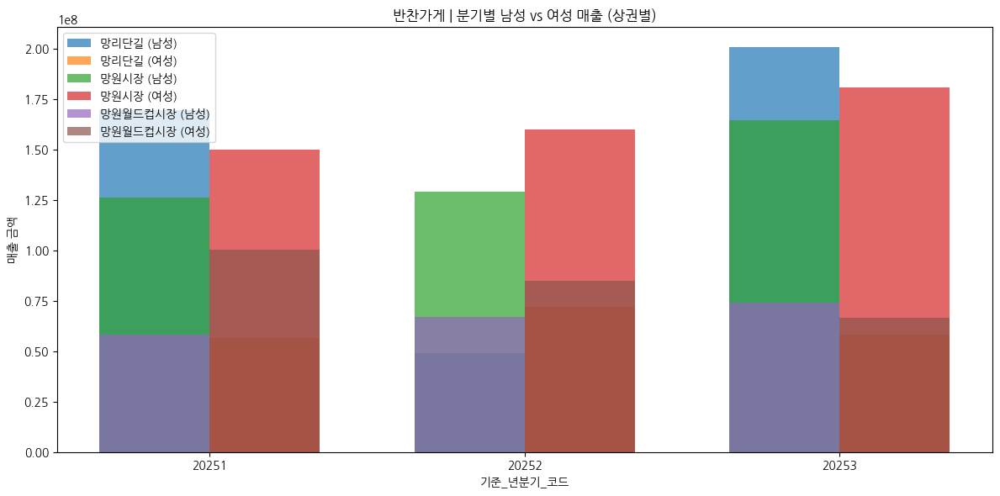

📊 업종: 청과상


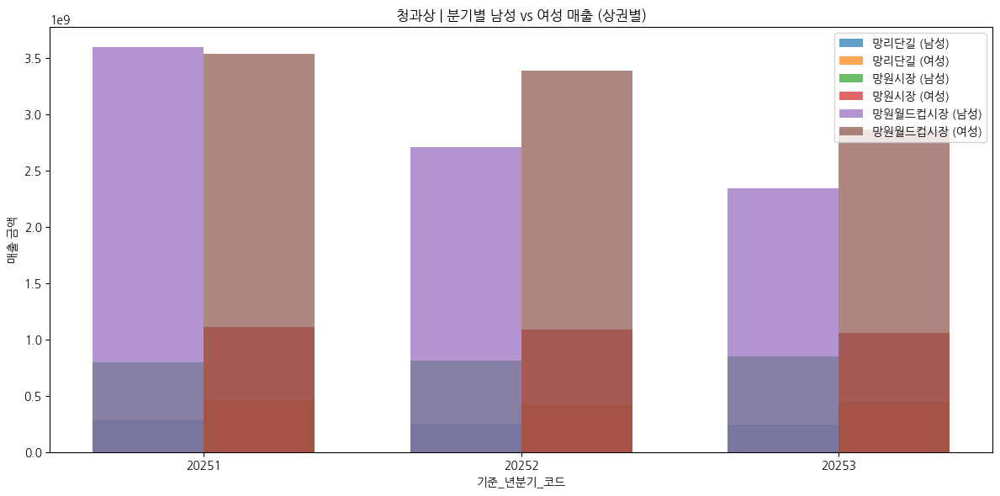

📊 업종: 육류판매


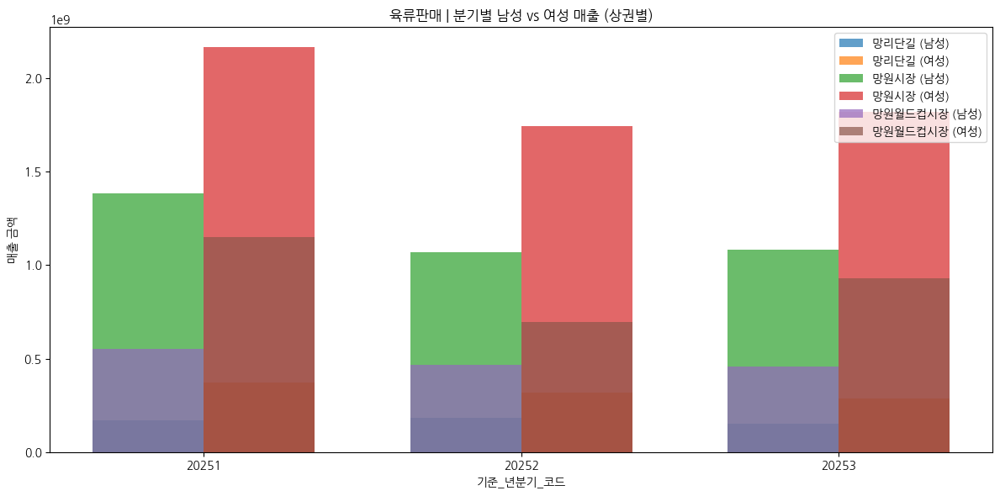

📊 업종: 편의점


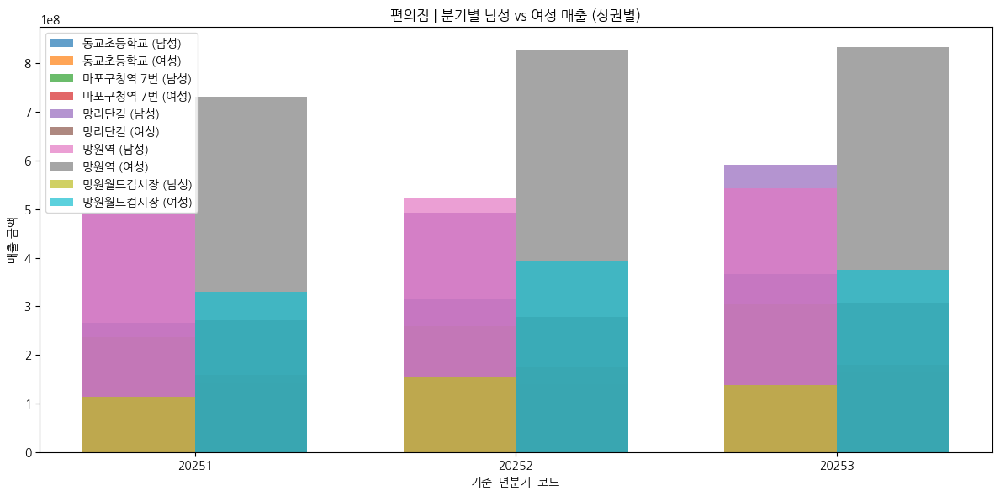

📊 업종: 슈퍼마켓


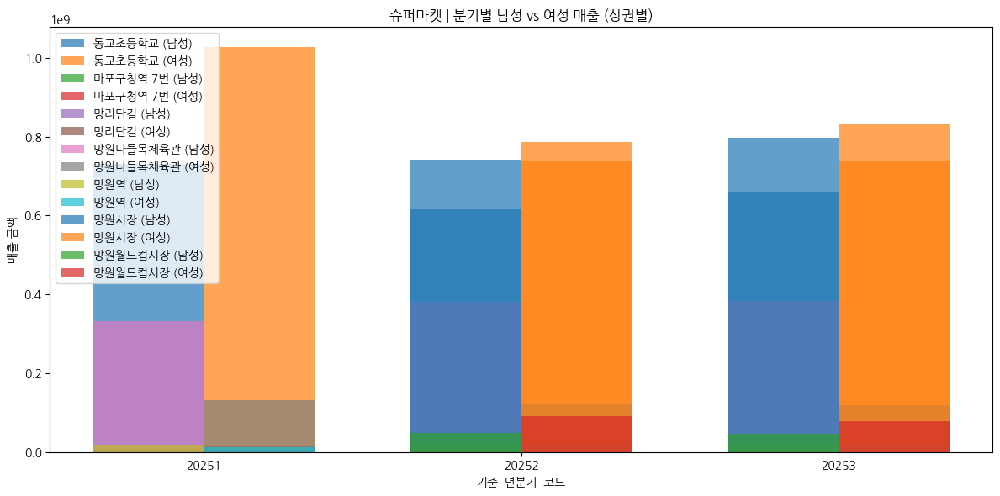

⚠️ 데이터 없음 → 사진관
📊 업종: 노래방


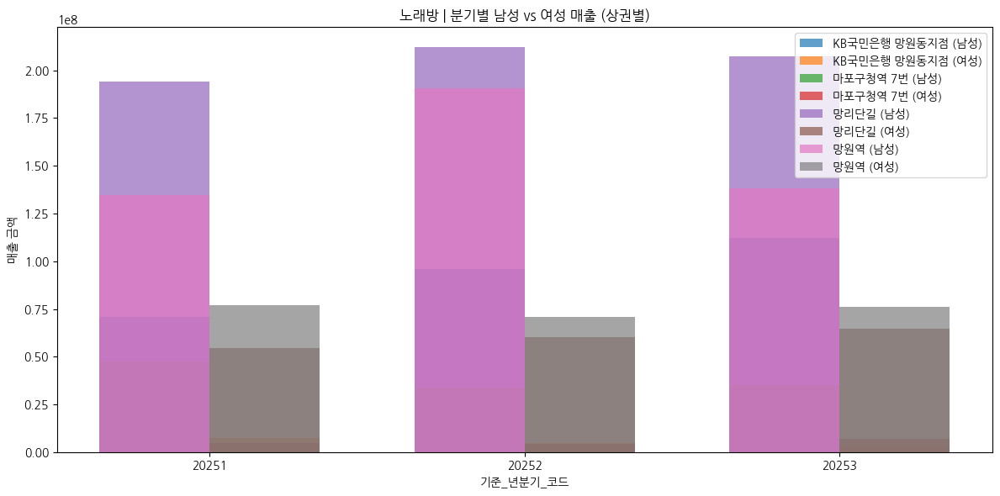

📊 업종: 세탁소


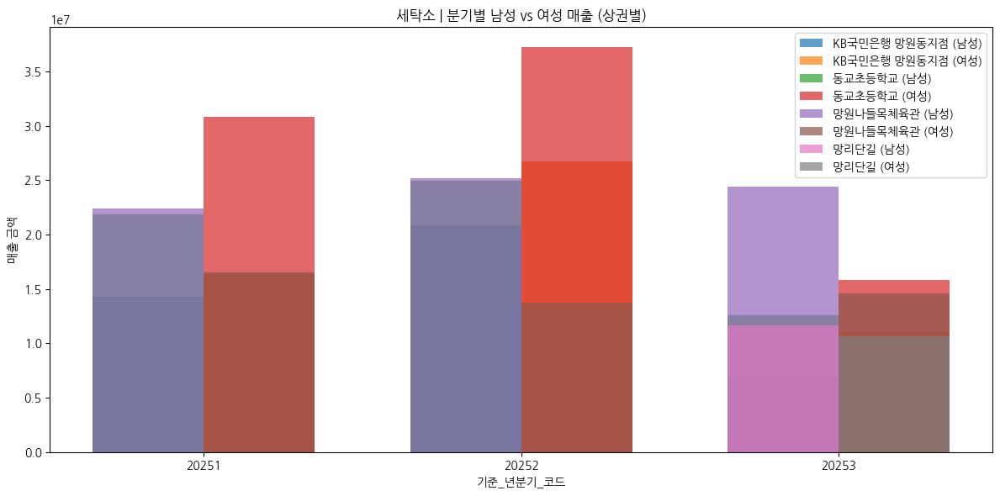

📊 업종: 피부관리실


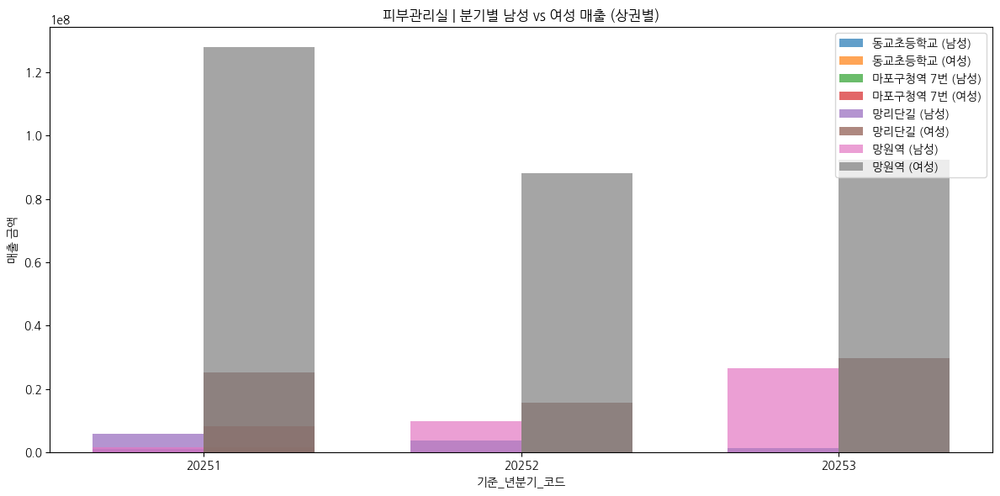

📊 업종: 네일숍


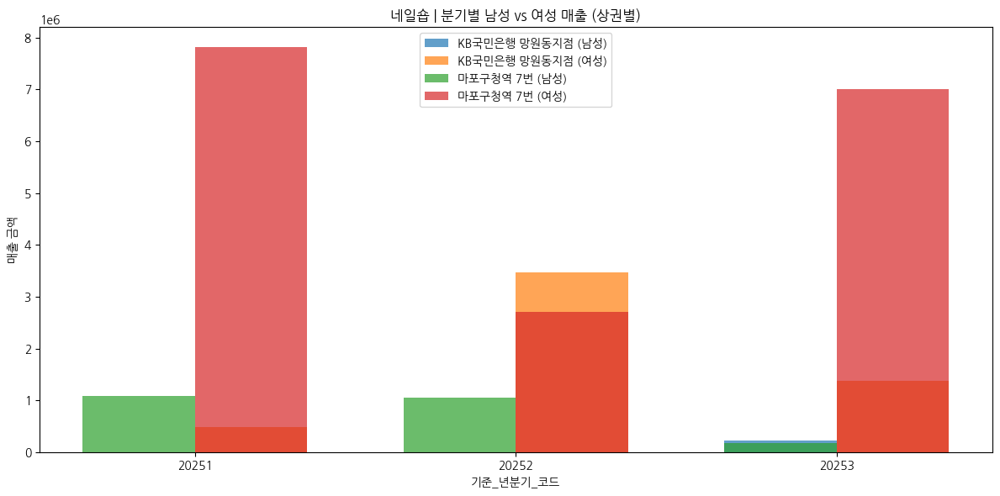

📊 업종: 미용실


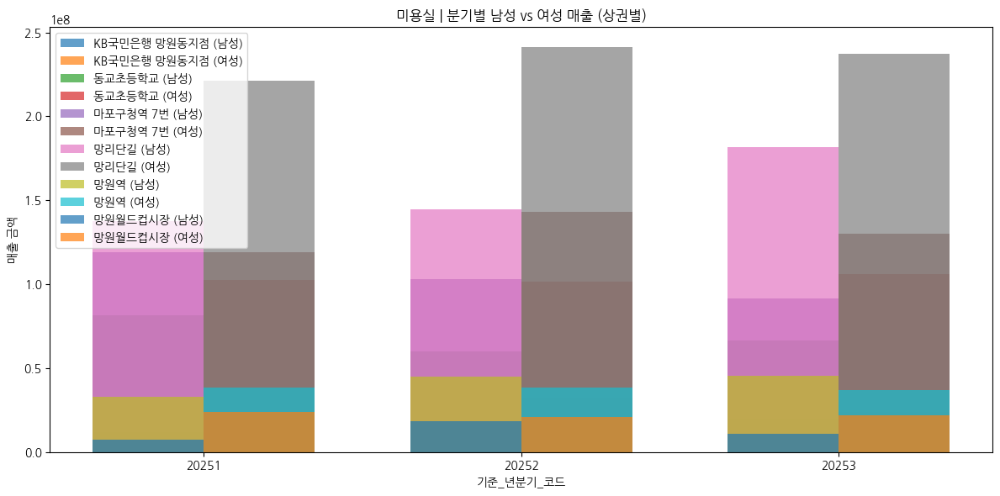

📊 업종: 스포츠클럽


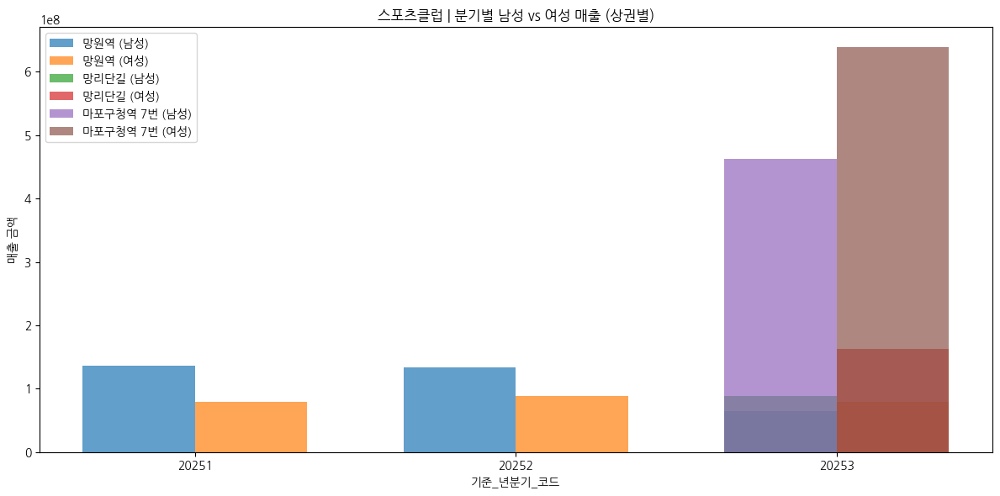

⚠️ 데이터 없음 → 복권방
⚠️ 데이터 없음 → 기타 오락장
📊 업종: PC방


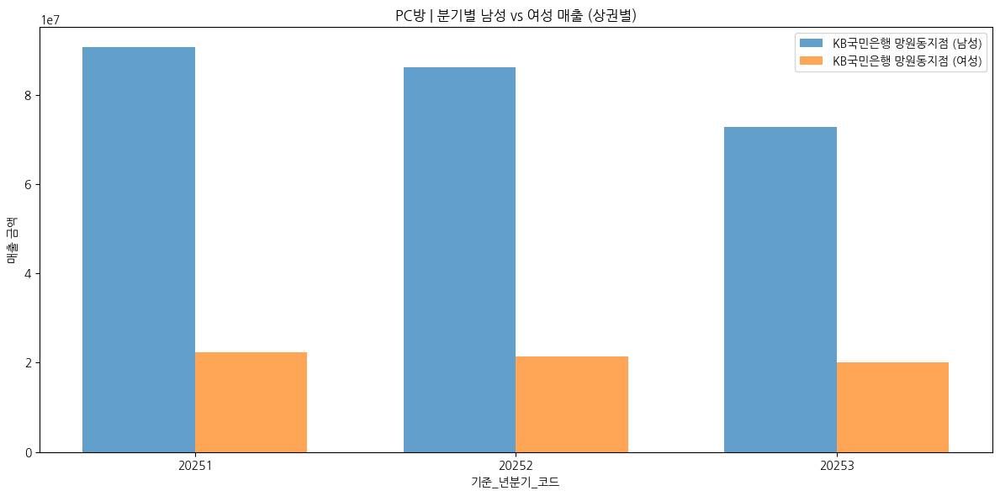

📊 업종: 당구장


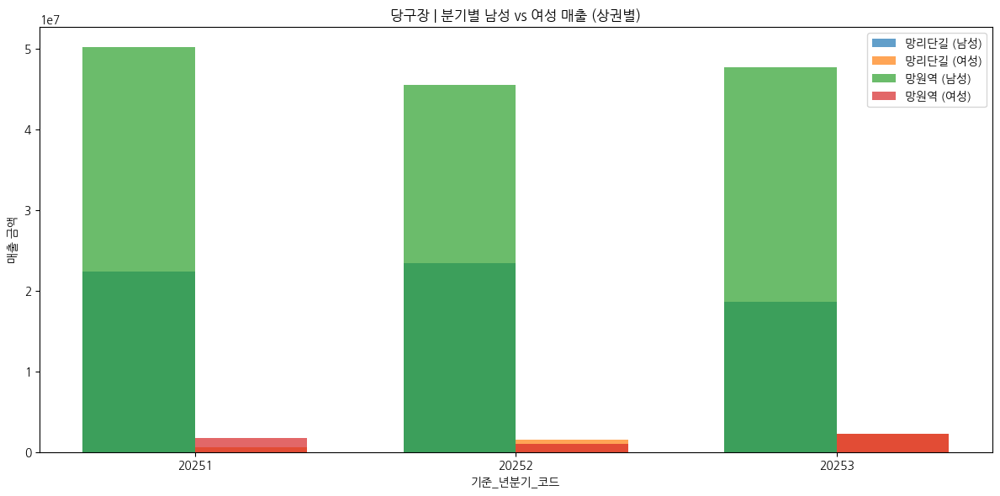

📊 업종: 한의원


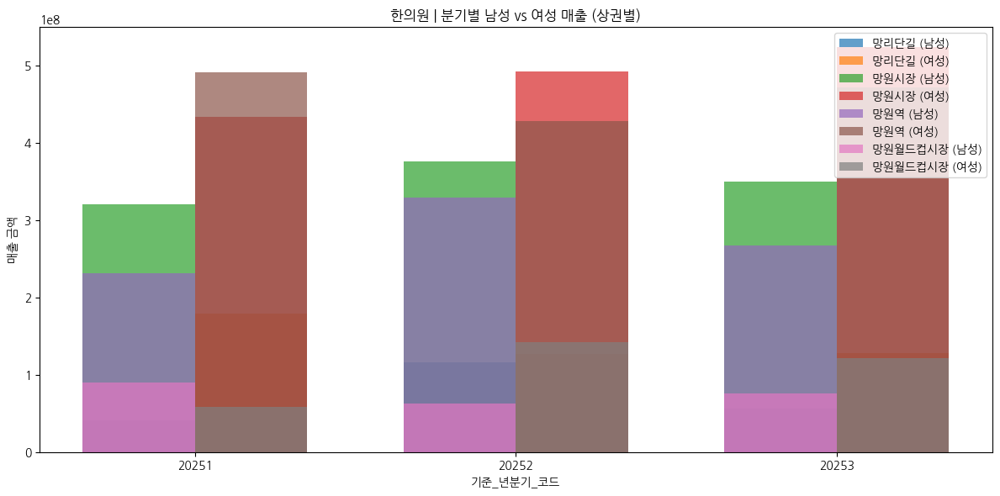

📊 업종: 일반교습학원


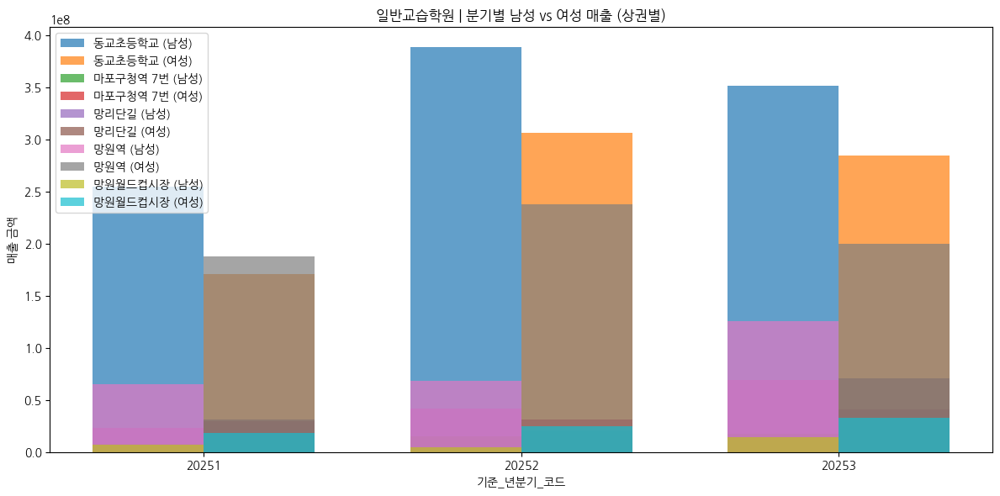

📊 업종: 커피-음료


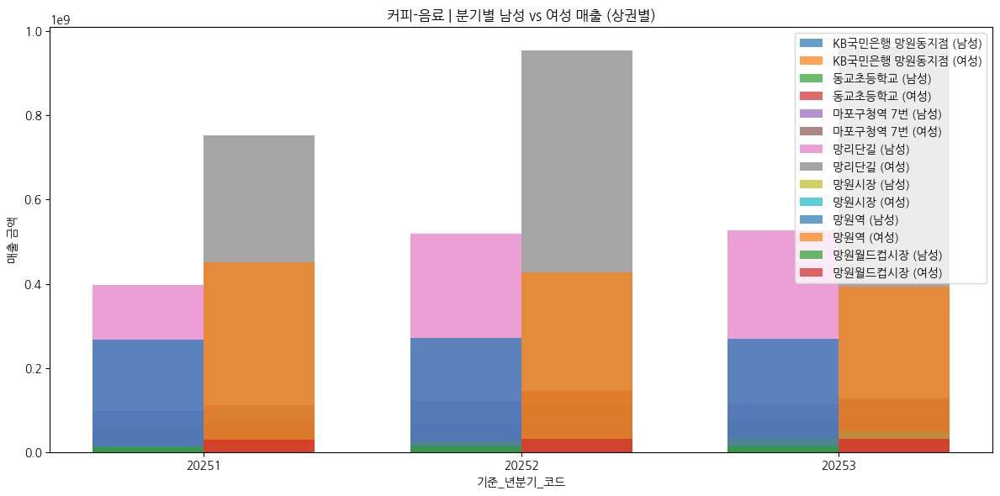

📊 업종: 호프-간이주점


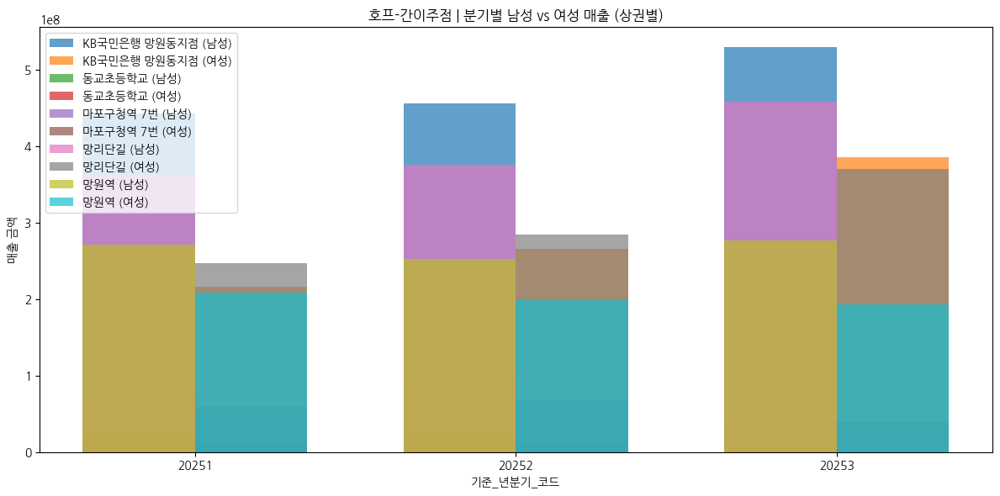

📊 업종: 분식전문점


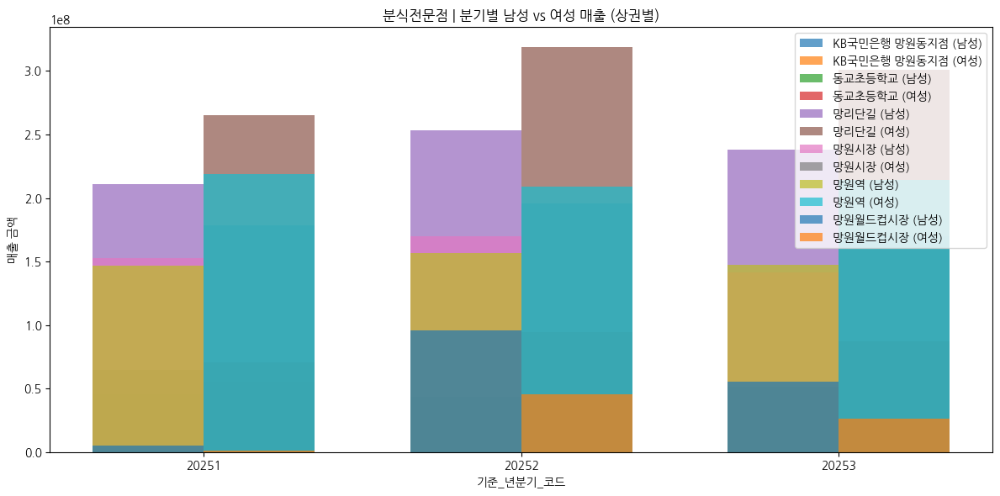

📊 업종: 치킨전문점


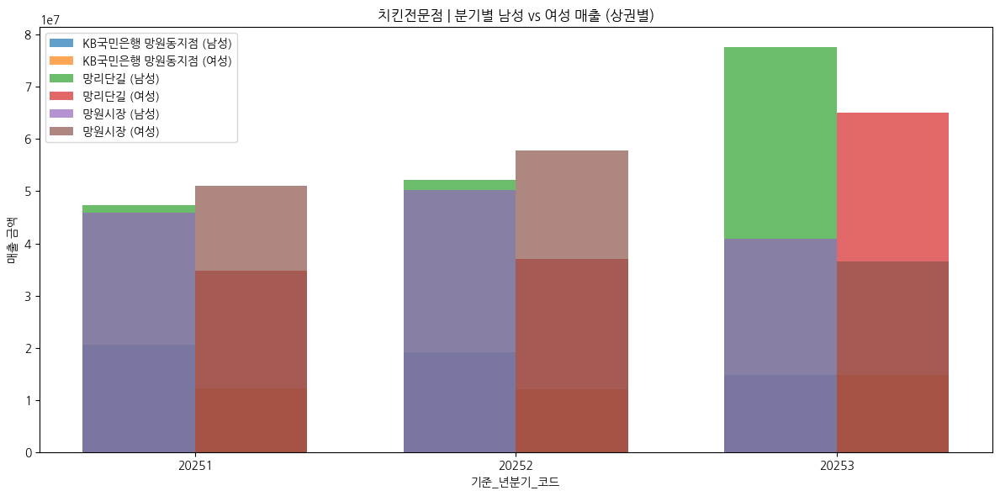

📊 업종: 패스트푸드점


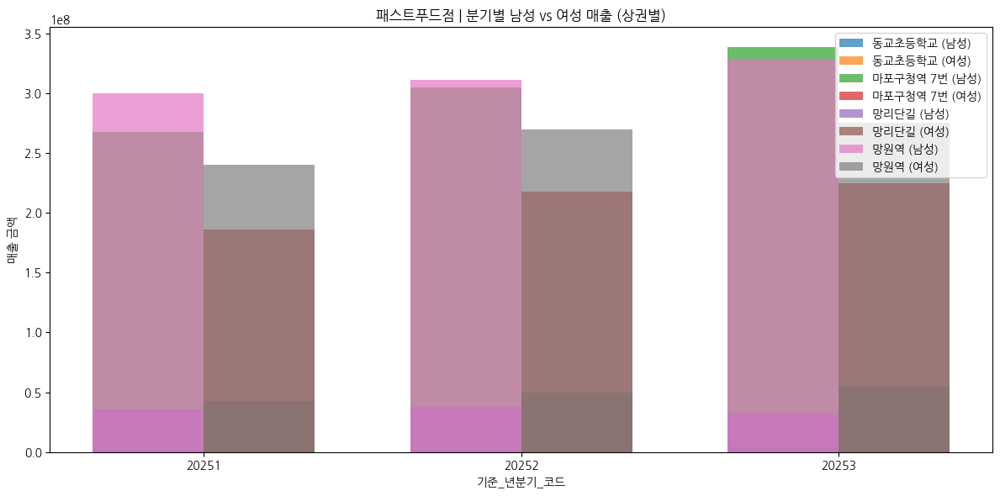

📊 업종: 제과점


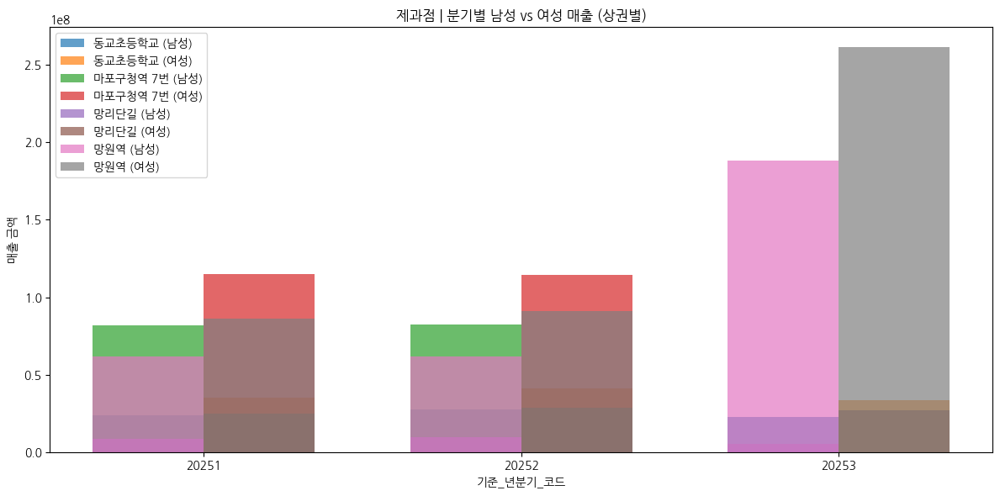

📊 업종: 양식음식점


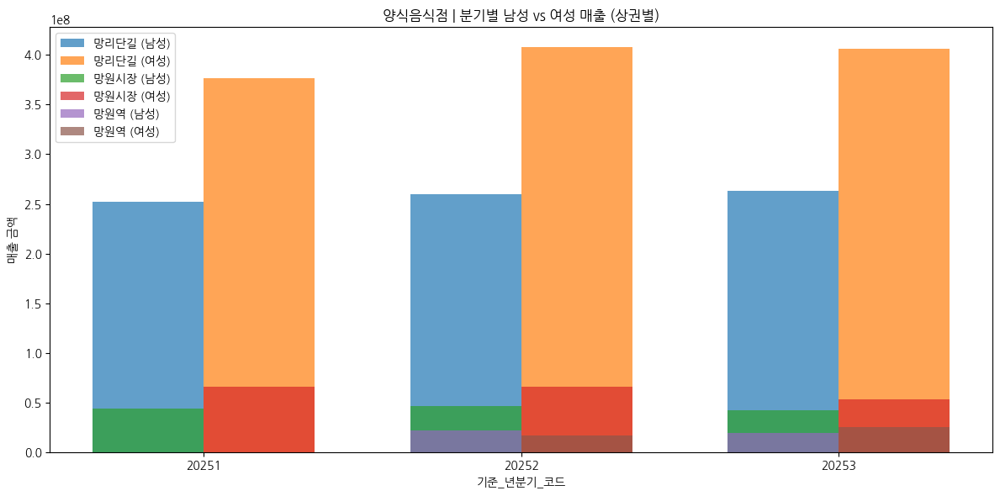

📊 업종: 일식음식점


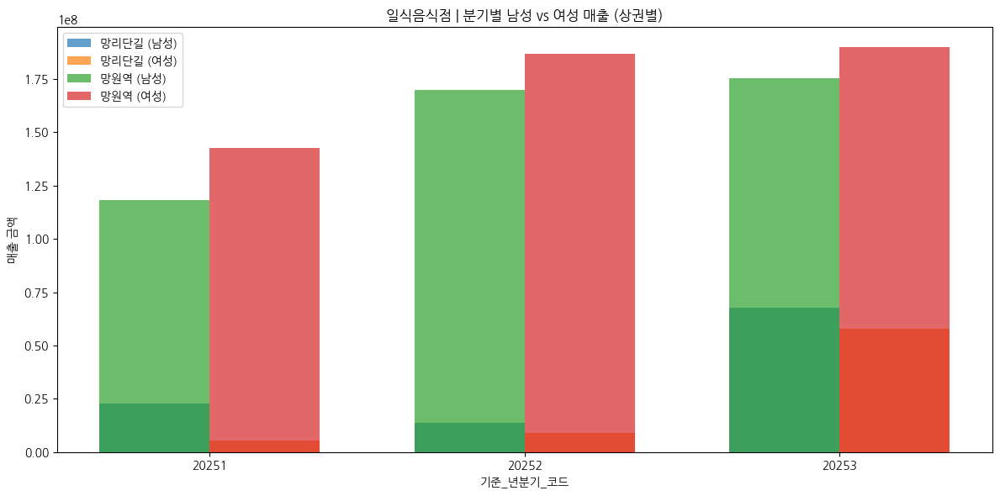

📊 업종: 중식음식점


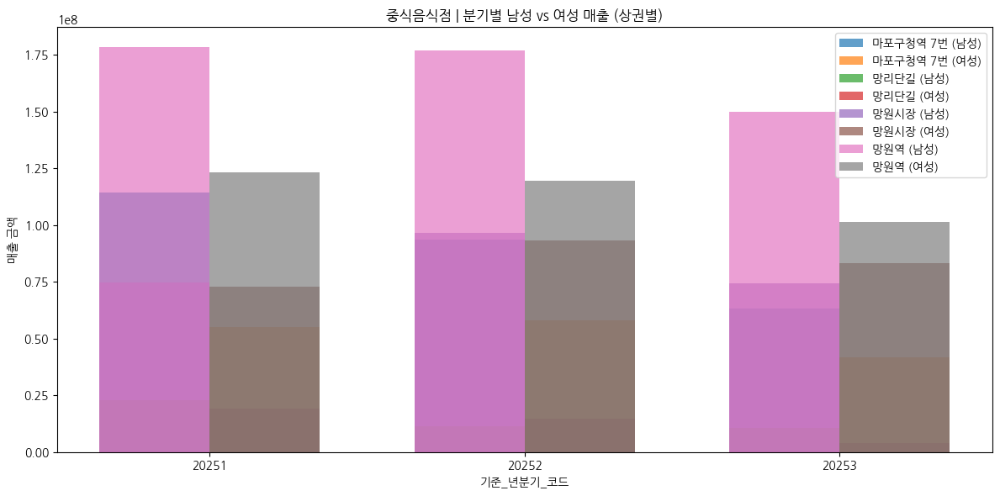

📊 업종: 한식음식점


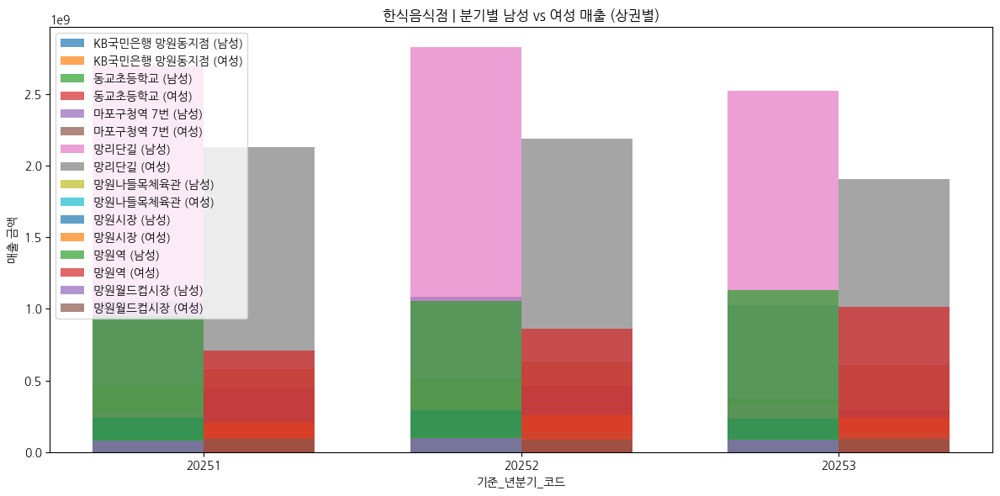

📊 업종: 화초


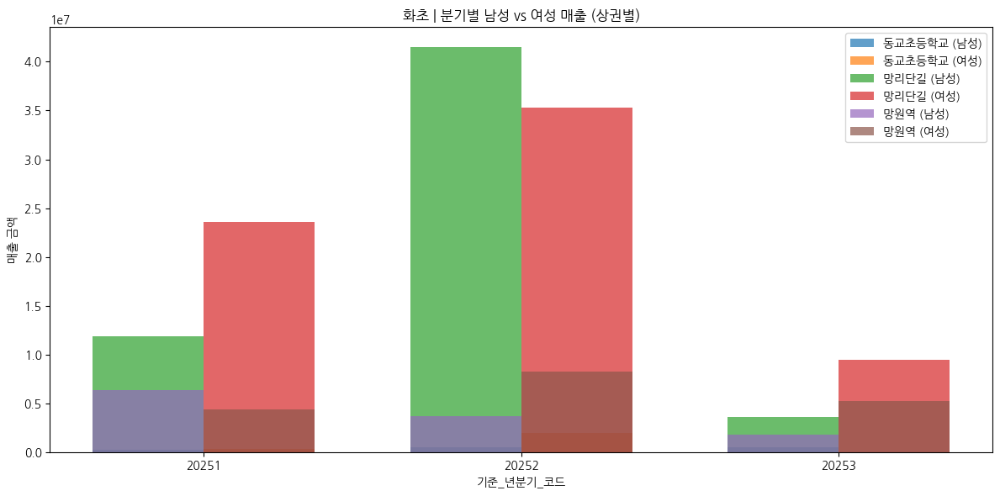

⚠️ 데이터 없음 → 완구
📊 업종: 문구


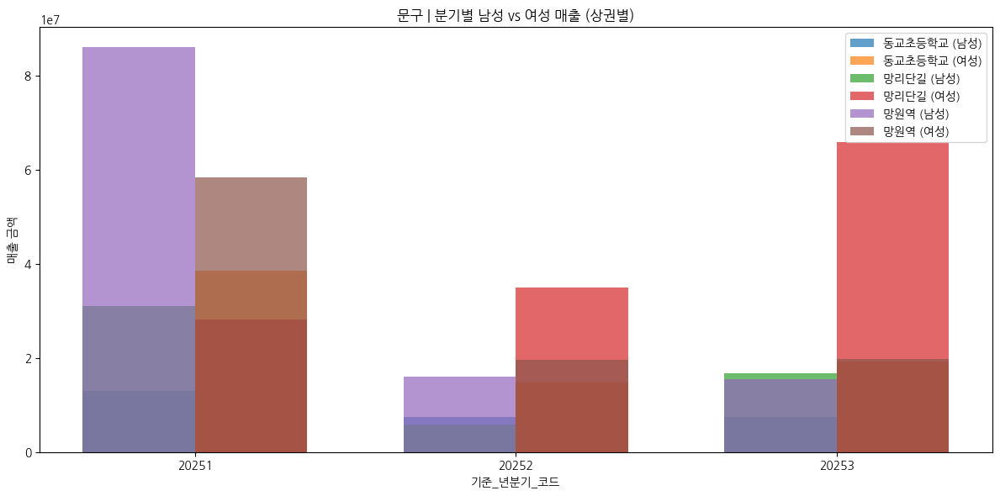

⚠️ 데이터 없음 → 유아의류
📊 업종: 수산물판매


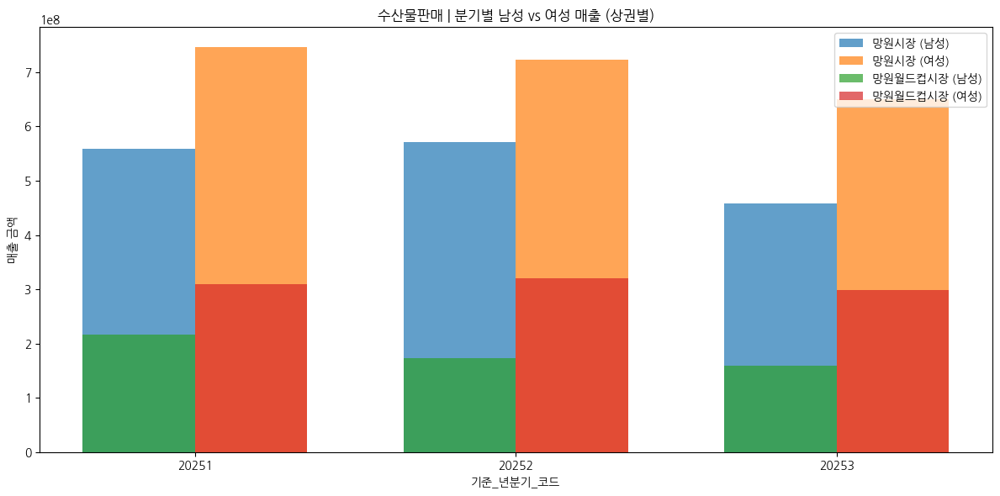

⚠️ 데이터 없음 → 독서실
⚠️ 데이터 없음 → 동물병원
⚠️ 데이터 없음 → 골프연습장


In [11]:
for industry in target_industries:
    if industry not in grouped["서비스_업종_코드_명"].unique():
        print(f"⚠️ 데이터 없음 → {industry}")
        continue

    print(f"📊 업종: {industry}")

    plot_gender_sales_side_by_side(industry)


In [15]:
existing_industries = set(grouped["서비스_업종_코드_명"].unique())

In [16]:
missing_industries = [
    ind for ind in target_industries
    if ind not in existing_industries
]

print("데이터에 없는 업종 개수:", len(missing_industries))
missing_industries


데이터에 없는 업종 개수: 8


['사진관', '복권방', '기타 오락장', '완구', '유아의류', '독서실', '동물병원', '골프연습장']

# 분기/상권별 연령대별 매출 차이

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

age_cols = [
    "연령대_10_매출_금액",
    "연령대_20_매출_금액",
    "연령대_30_매출_금액",
    "연령대_40_매출_금액",
    "연령대_50_매출_금액",
    "연령대_60_이상_매출_금액",
]

need_cols = ["기준_년분기_코드", "상권_코드_명"] + age_cols
missing = [c for c in need_cols if c not in df.columns]
assert not missing, f"필요 컬럼 누락: {missing}"

# 숫자형 캐스팅(혹시 문자열이면)
for c in age_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

age_by_q_area = (
    df.groupby(["기준_년분기_코드", "상권_코드_명"], as_index=False)[age_cols]
      .sum()
)

age_by_q_area.head()


,기준_년분기_코드,상권_코드_명,연령대_10_매출_금액,연령대_20_매출_금액,연령대_30_매출_금액,연령대_40_매출_금액,연령대_50_매출_금액,연령대_60_이상_매출_금액
0,20251,KB국민은행 망원동지점,17839756,606431651,1293812092,1002508245,1312492371,899600689
1,20251,동교초등학교,11826320,431098548,949816968,1438527383,945384371,907694586
2,20251,마포구청역 7번,13540232,316281115,715469771,704953292,841288380,775952680
3,20251,망리단길,51747168,2525825069,4073694357,2498785271,2513633816,2428710967
4,20251,망원나들목체육관,1834240,106806377,243919606,164129975,111329111,93587605


# 분기/상권별로 어느 상권에 어느 연령층이 많은지 알 수 있음

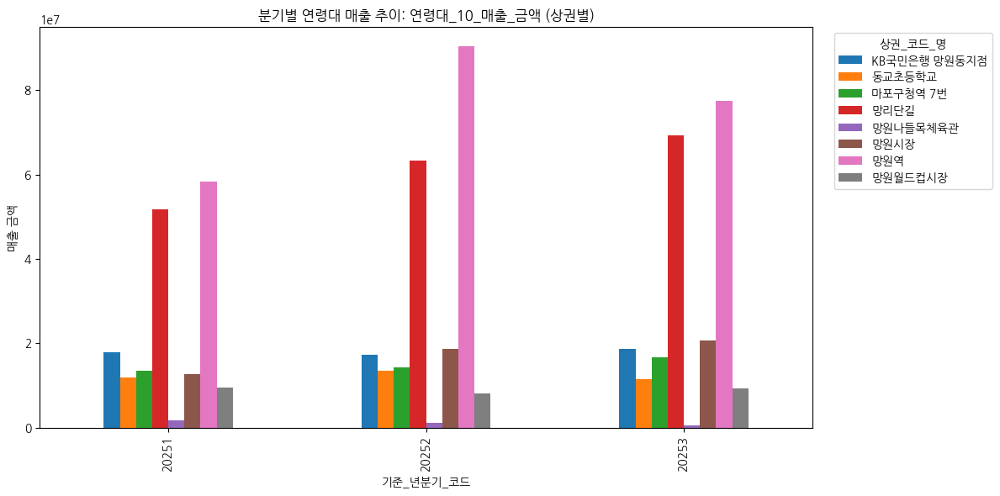

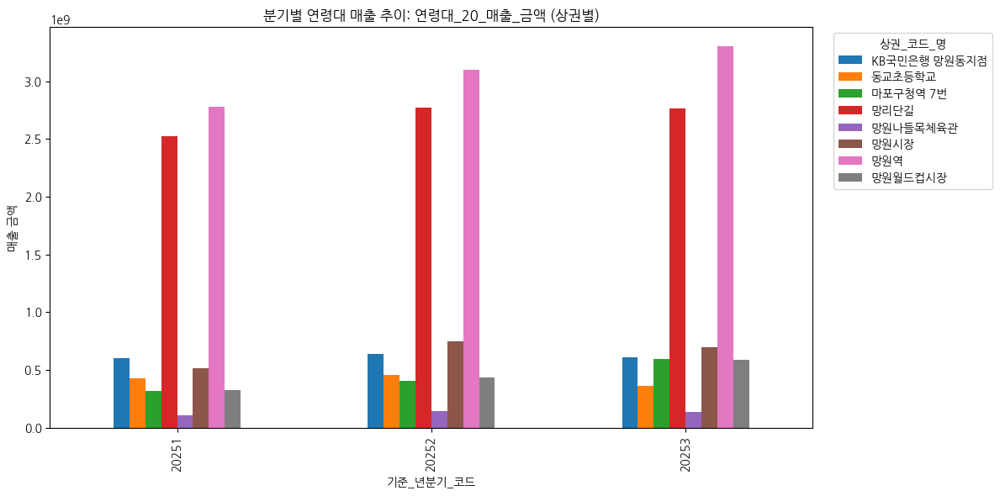

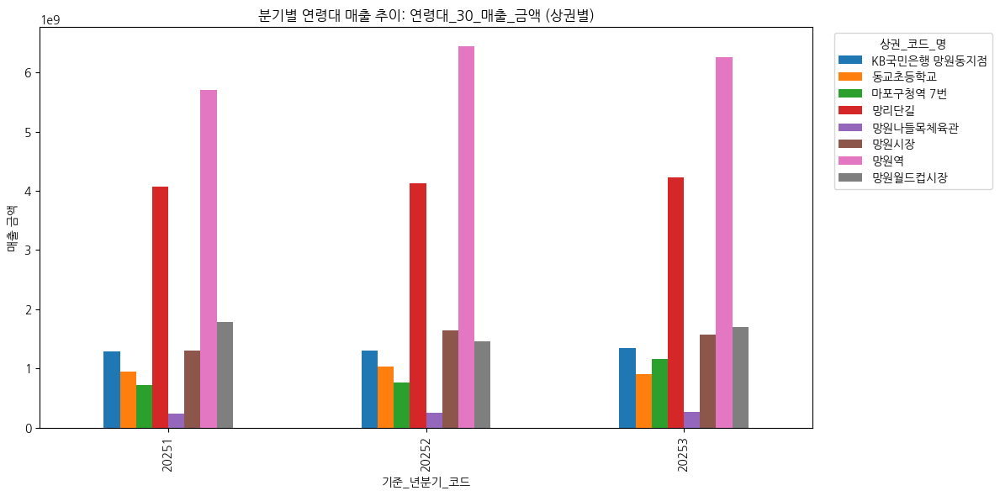

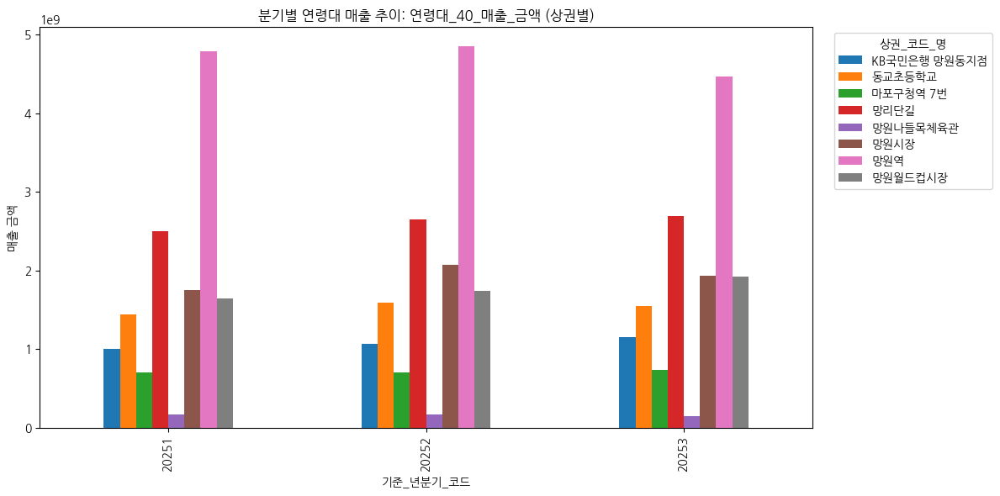

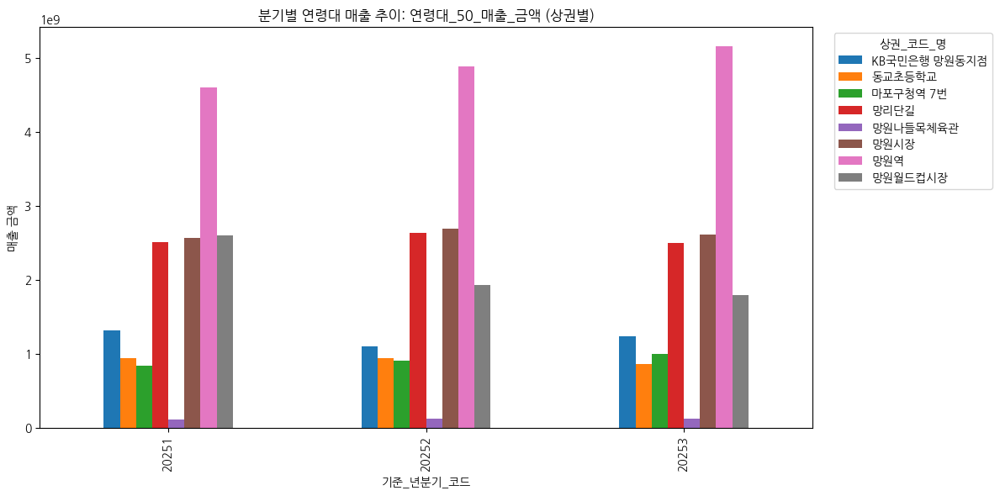

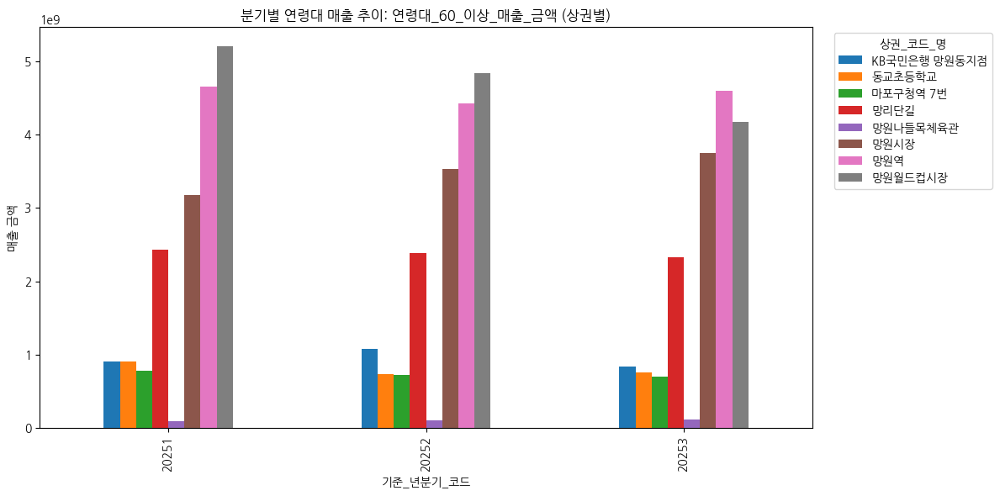

In [21]:
# 분기 정렬을 위해 문자열/숫자 혼용 방지
age_by_q_area["기준_년분기_코드"] = pd.to_numeric(age_by_q_area["기준_년분기_코드"], errors="coerce")

# (선택) 상권이 너무 많으면 범례/가독성 터지니까, 상위 N개 상권만 보고 싶을 때:
# topN = 5
# top_areas = (age_by_q_area.groupby("상권_코드_명")[age_cols].sum().sum(axis=1)
#              .sort_values(ascending=False).head(topN).index)
# age_plot_df = age_by_q_area[age_by_q_area["상권_코드_명"].isin(top_areas)].copy()
age_plot_df = age_by_q_area.copy()

for age_col in age_cols:
    pivot = (
        age_plot_df.pivot_table(
            index="기준_년분기_코드",
            columns="상권_코드_명",
            values=age_col,
            aggfunc="sum",
            fill_value=0
        )
        .sort_index()
    )

    ax = pivot.plot(kind="bar", figsize=(12, 6))
    ax.set_title(f"분기별 연령대 매출 추이: {age_col} (상권별)")
    ax.set_xlabel("기준_년분기_코드")
    ax.set_ylabel("매출 금액")
    ax.legend(title="상권_코드_명", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


# 위 그래프에서 더 자세하게 상권을 업종별로 나눠서 어느 연령층이 어느 업종에 많이 소비했는지 알 수 있음

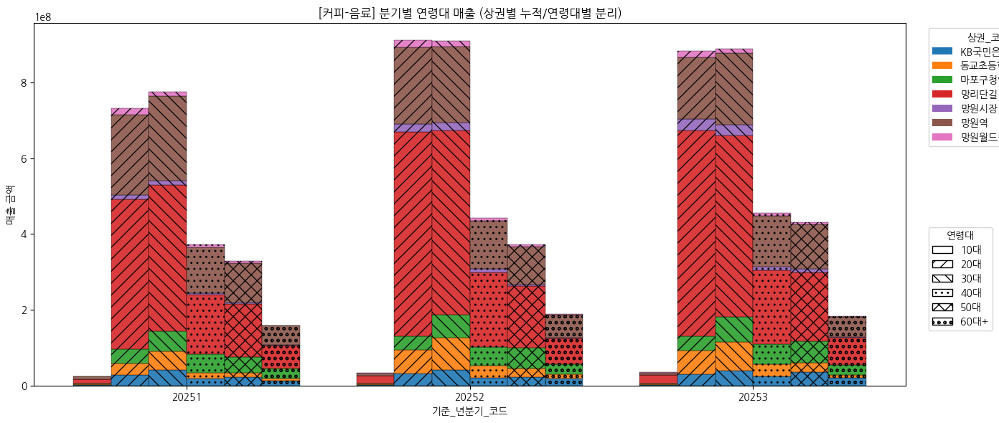

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

age_cols = [
    "연령대_10_매출_금액",
    "연령대_20_매출_금액",
    "연령대_30_매출_금액",
    "연령대_40_매출_금액",
    "연령대_50_매출_금액",
    "연령대_60_이상_매출_금액",
]
age_labels = ["10대", "20대", "30대", "40대", "50대", "60대+"]
hatches = ["", "//", "\\\\", "..", "xx", "oo"]  # 연령대 구분용(색은 상권에 씀)

need_cols = ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"] + age_cols
missing = [c for c in need_cols if c not in df.columns]
assert not missing, f"필요 컬럼 누락: {missing}"

# 숫자화
tmp = df.copy()
tmp["기준_년분기_코드"] = pd.to_numeric(tmp["기준_년분기_코드"], errors="coerce")
for c in age_cols:
    tmp[c] = pd.to_numeric(tmp[c], errors="coerce")

# 업종별 집계 테이블(분기×업종×상권 단위로 연령대 매출 합)
agg = (
    tmp.groupby(["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"], as_index=False)[age_cols]
       .sum()
)

def plot_age_area_stacked_by_industry(industry_name, top_areas=None):
    sub = agg[agg["서비스_업종_코드_명"] == industry_name].copy()
    if sub.empty:
        print(f"⚠️ 데이터 없음: {industry_name}")
        return

    # 상권이 너무 많으면 보기 어려우니 (원하면) 매출 상위 N 상권만
    if top_areas is not None:
        area_rank = sub.groupby("상권_코드_명")[age_cols].sum().sum(axis=1).sort_values(ascending=False)
        keep_areas = area_rank.head(top_areas).index
        sub = sub[sub["상권_코드_명"].isin(keep_areas)].copy()

    quarters = sorted(sub["기준_년분기_코드"].dropna().unique())
    areas = list(sub["상권_코드_명"].unique())

    # 위치 세팅: 분기마다 연령대 6개 bar를 옆으로 배치
    x = np.arange(len(quarters))
    total_group_width = 0.8
    bar_w = total_group_width / len(age_cols)
    offsets = (np.arange(len(age_cols)) - (len(age_cols)-1)/2) * bar_w

    # 상권 색상(기본 사이클 사용)
    color_cycle = plt.rcParams["axes.prop_cycle"].by_key().get("color", [])
    if len(color_cycle) == 0:
        color_cycle = [None] * max(1, len(areas))

    area_color = {a: color_cycle[i % len(color_cycle)] for i, a in enumerate(areas)}

    plt.figure(figsize=(14, 6))

    # 연령대별로 "bar(=분기×연령대)"를 만들고, 그 안에 상권별로 stack
    for j, (age_col, age_lab) in enumerate(zip(age_cols, age_labels)):
        bottoms = np.zeros(len(quarters), dtype=float)

        for area in areas:
            area_df = sub[sub["상권_코드_명"] == area]
            vals = []
            for q in quarters:
                v = area_df.loc[area_df["기준_년분기_코드"] == q, age_col].sum()
                vals.append(v if pd.notna(v) else 0.0)
            vals = np.array(vals, dtype=float)

            plt.bar(
                x + offsets[j],
                vals,
                width=bar_w,
                bottom=bottoms,
                label=area,                 # 상권 범례용(중복은 아래에서 정리)
                color=area_color[area],
                hatch=hatches[j],          # 연령대는 hatch로 구분
                edgecolor="black",
                linewidth=0.3,
                alpha=0.9
            )
            bottoms += vals

    # x축 라벨: 분기
    plt.xticks(x, [str(int(q)) for q in quarters])
    plt.xlabel("기준_년분기_코드")
    plt.ylabel("매출 금액")
    plt.title(f"[{industry_name}] 분기별 연령대 매출 (상권별 누적/연령대별 분리)")

    ax = plt.gca()

    # ✅ 범례 2개 만들기
    # (1) 상권 범례(색)
    area_handles = [Patch(facecolor=area_color[a], label=a) for a in areas]
    legend1 = ax.legend(handles=area_handles, title="상권_코드_명", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.add_artist(legend1)

    # (2) 연령대 범례(hatch)
    age_handles = [Patch(facecolor="white", edgecolor="black", hatch=hatches[i], label=age_labels[i])
                   for i in range(len(age_labels))]
    ax.legend(handles=age_handles, title="연령대", bbox_to_anchor=(1.02, 0.45), loc="upper left")

    plt.tight_layout()
    plt.show()

# ---- 사용 예시 ----
# 업종 하나만 먼저 확인
plot_age_area_stacked_by_industry("커피-음료", top_areas=8)  # 상권 너무 많으면 top_areas 추천


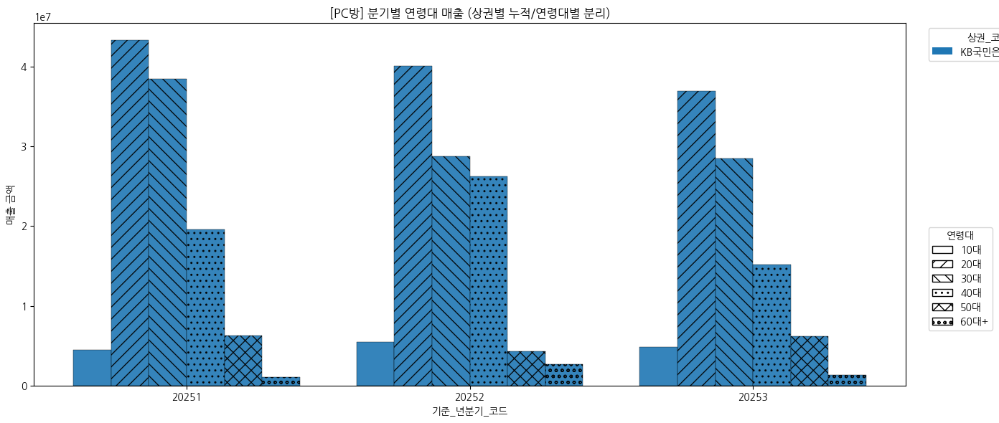

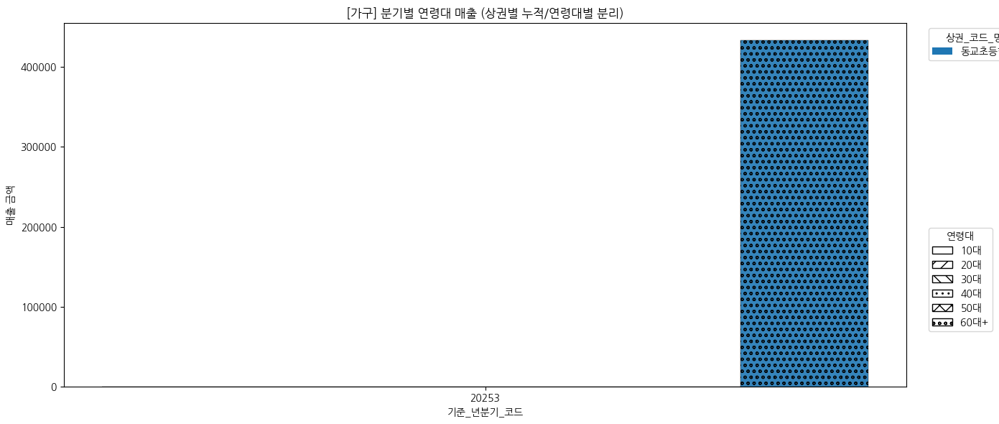

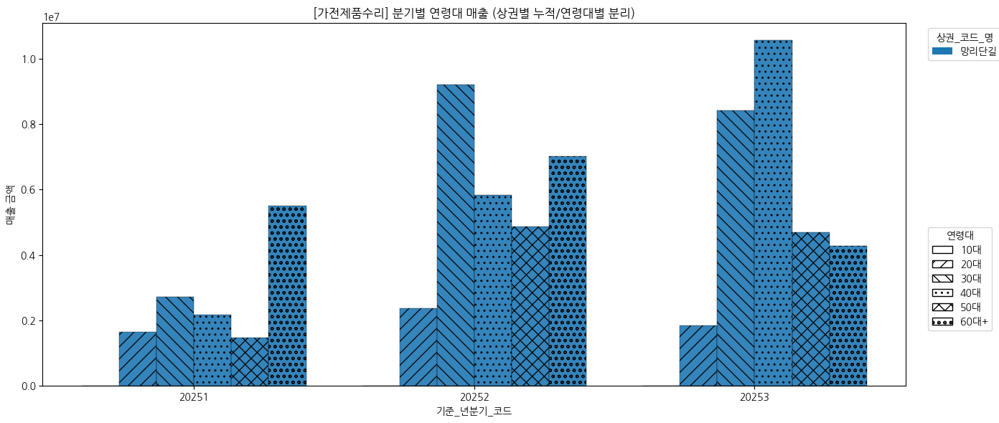

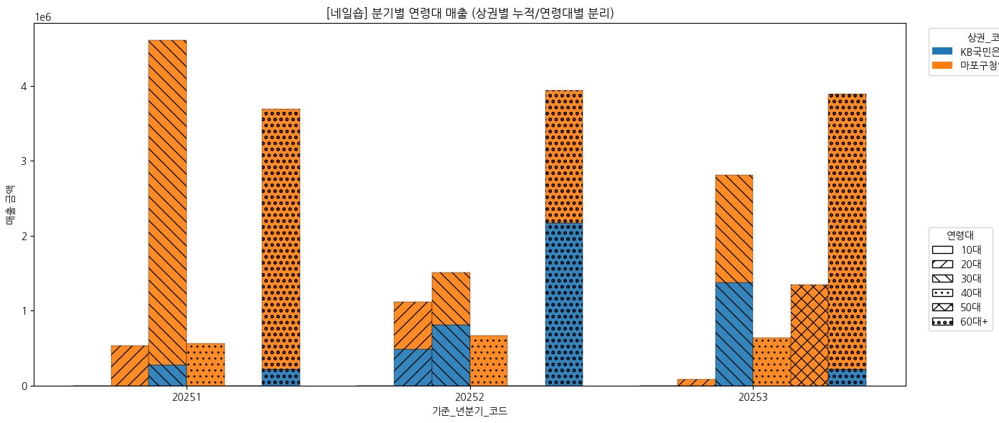

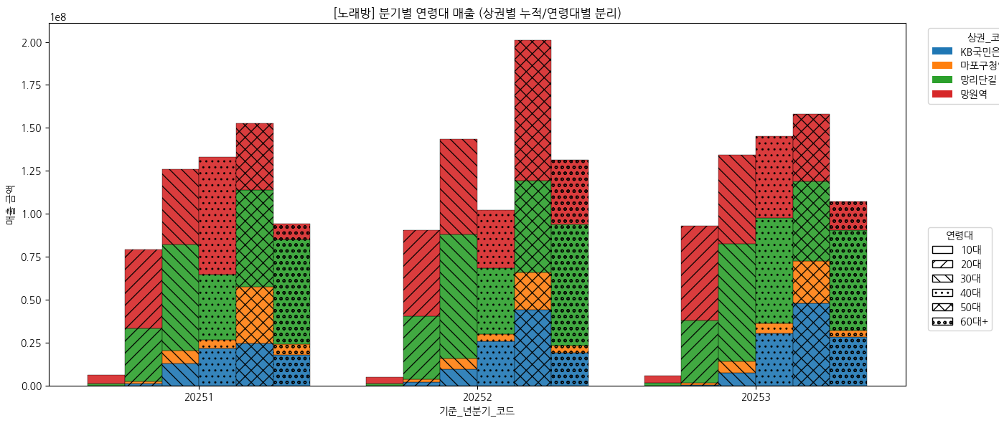

...

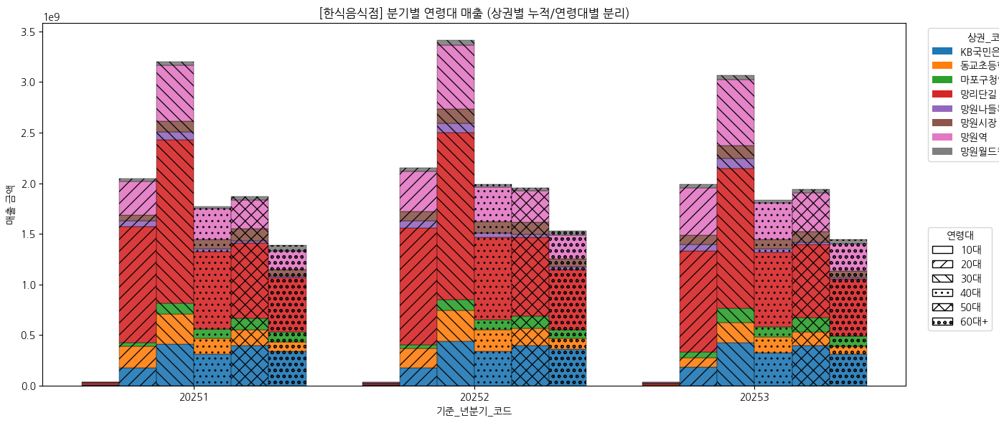

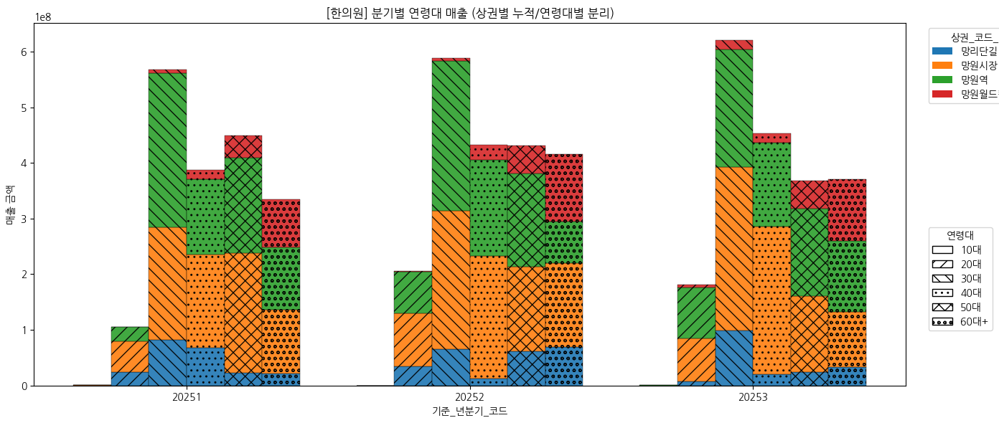

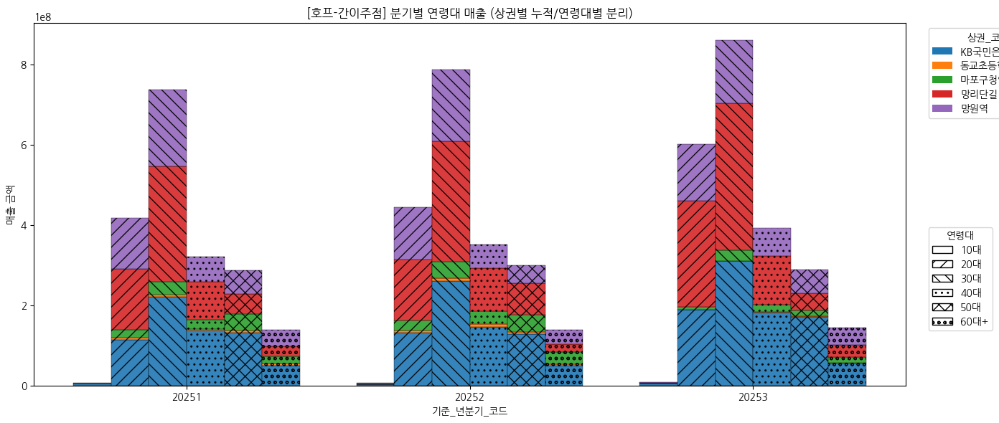

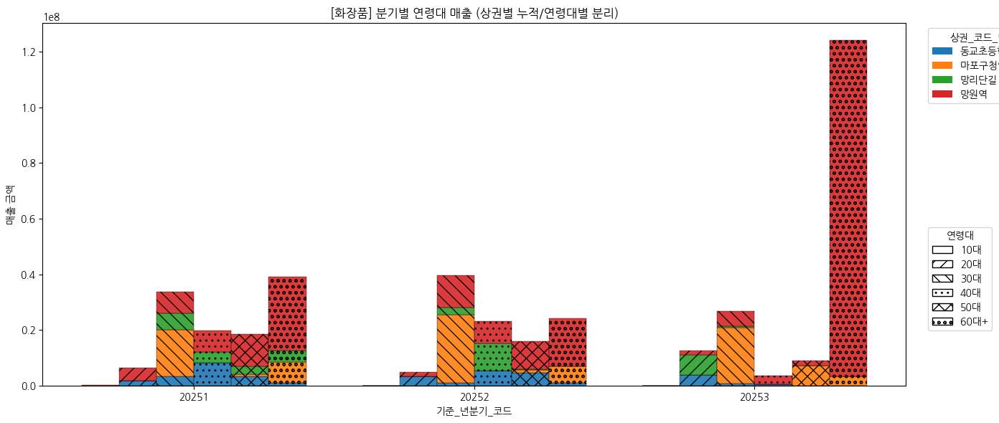

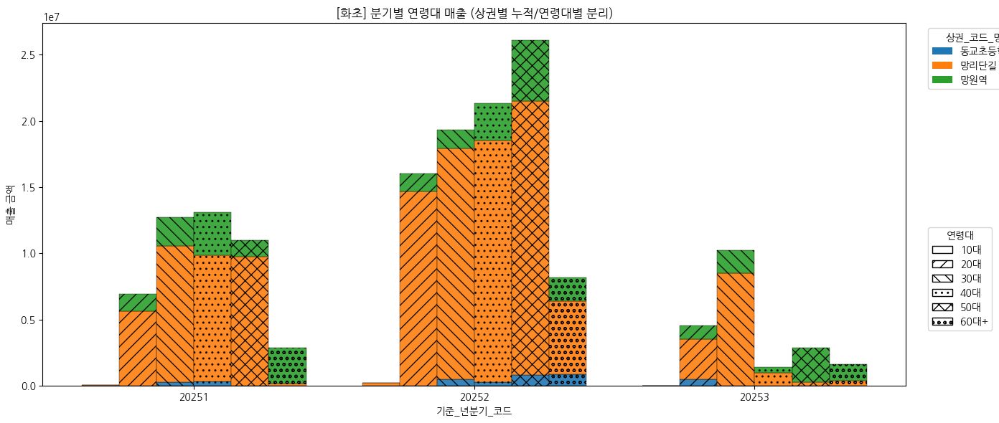

In [28]:
industries = sorted(agg["서비스_업종_코드_명"].unique())
for ind in industries:
    plot_age_area_stacked_by_industry(ind, top_areas=8)


# 분기별/상권별/요일별 매출 금액. 업종별로 나눠서

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weekday_cols = [
    "월요일_매출_금액",
    "화요일_매출_금액",
    "수요일_매출_금액",
    "목요일_매출_금액",
    "금요일_매출_금액",
    "토요일_매출_금액",
    "일요일_매출_금액",
]

need_cols = ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"] + weekday_cols
missing = [c for c in need_cols if c not in df.columns]
assert not missing, f"필요 컬럼 누락: {missing}"

# 숫자형 캐스팅
tmp = df.copy()
tmp["기준_년분기_코드"] = pd.to_numeric(tmp["기준_년분기_코드"], errors="coerce")
for c in weekday_cols:
    tmp[c] = pd.to_numeric(tmp[c], errors="coerce")


In [34]:
weekday_agg = (
    tmp.groupby(
        ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"],
        as_index=False
    )[weekday_cols]
    .sum()
)


In [35]:
def plot_weekday_sales_by_industry(industry_name):
    sub = weekday_agg[weekday_agg["서비스_업종_코드_명"] == industry_name].copy()

    if sub.empty:
        print(f"⚠️ 데이터 없음: {industry_name}")
        return

    # 상권별 합산 → 분기 기준 요일 패턴
    plot_df = (
        sub.groupby("기준_년분기_코드")[weekday_cols]
           .sum()
           .sort_index()
    )

    quarters = plot_df.index.astype(int).astype(str)
    x = np.arange(len(quarters))

    bar_width = 0.11  # 요일 7개라 좁게
    offsets = np.linspace(-3, 3, len(weekday_cols)) * bar_width

    plt.figure(figsize=(14, 6))

    for i, day in enumerate(weekday_cols):
        plt.bar(
            x + offsets[i],
            plot_df[day],
            width=bar_width,
            label=day.replace("_매출_금액", "")
        )

    plt.xticks(x, quarters)
    plt.xlabel("기준_년분기_코드")
    plt.ylabel("매출 금액")
    plt.title(f"[{industry_name}] 분기별 요일 매출 패턴")
    plt.legend(title="요일")
    plt.tight_layout()
    plt.show()


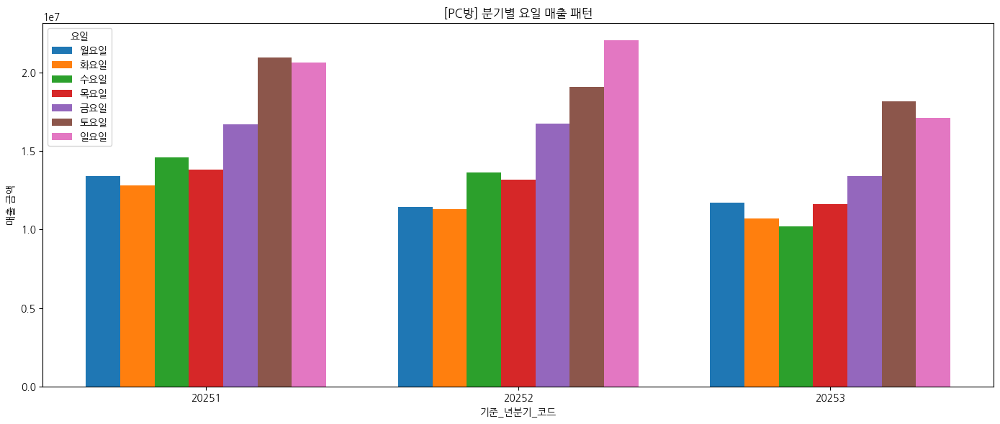

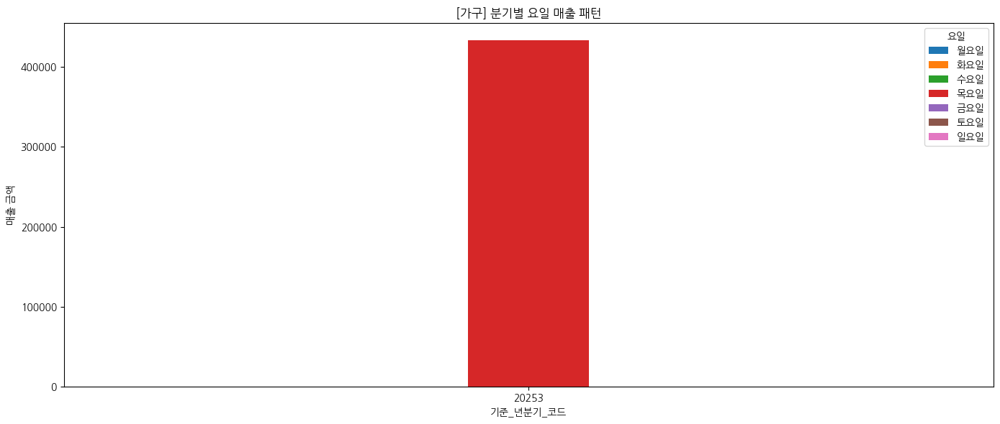

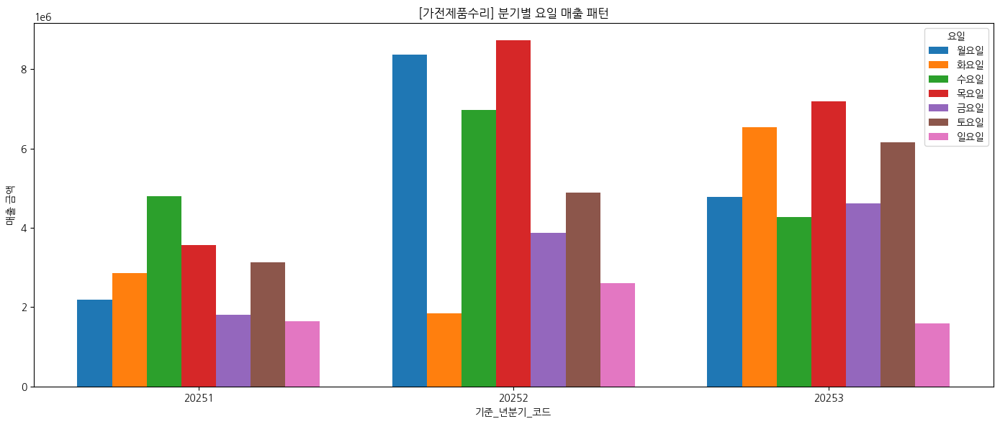

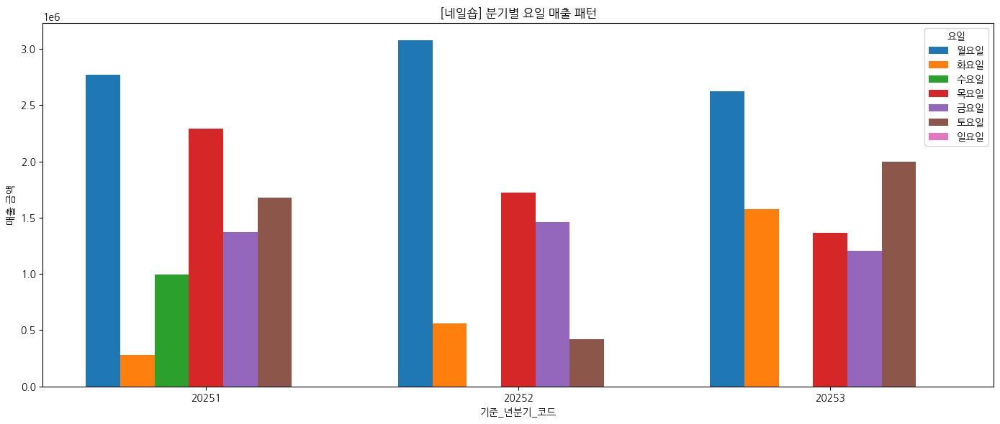

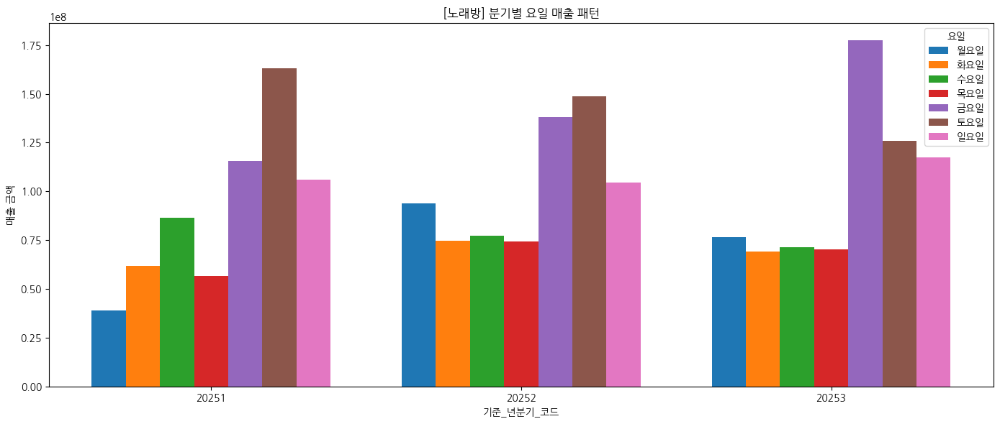

...

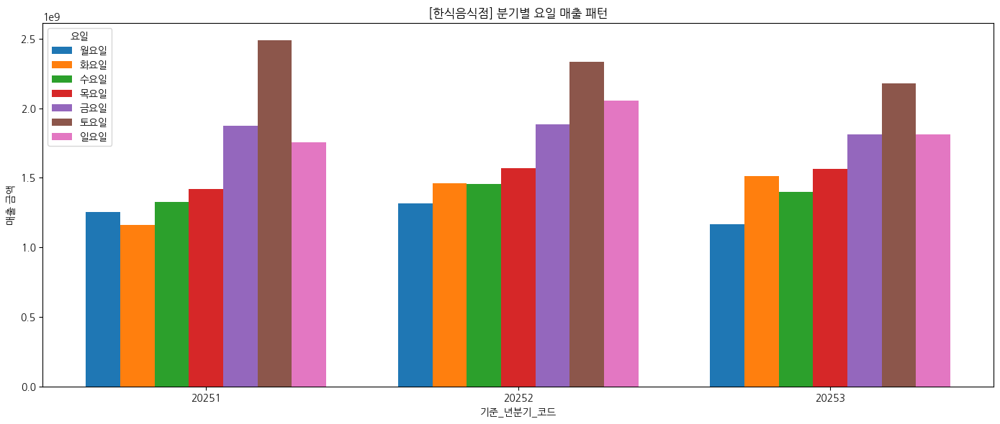

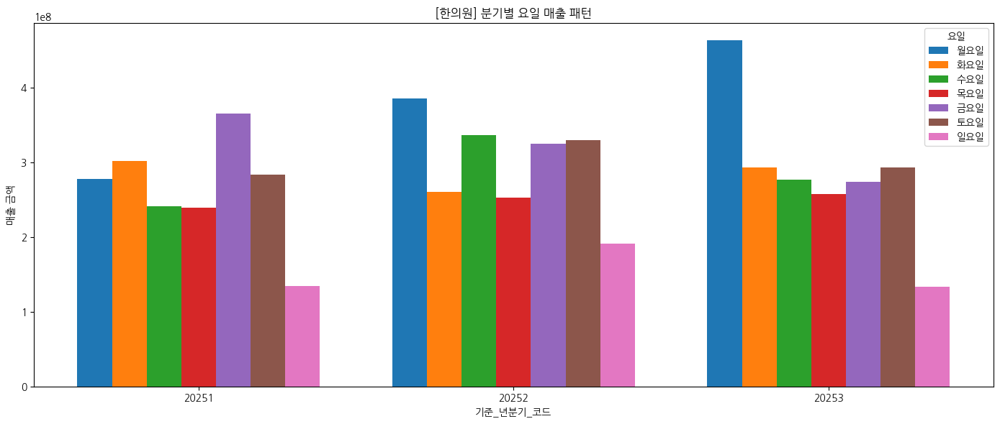

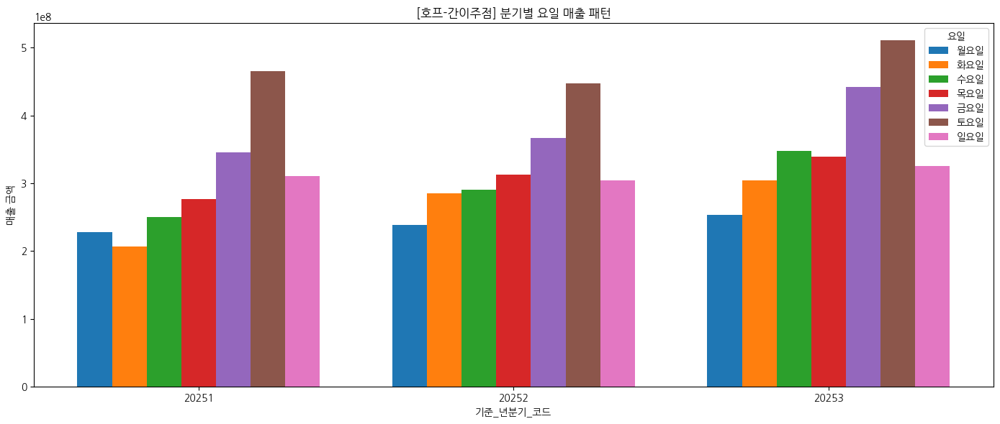

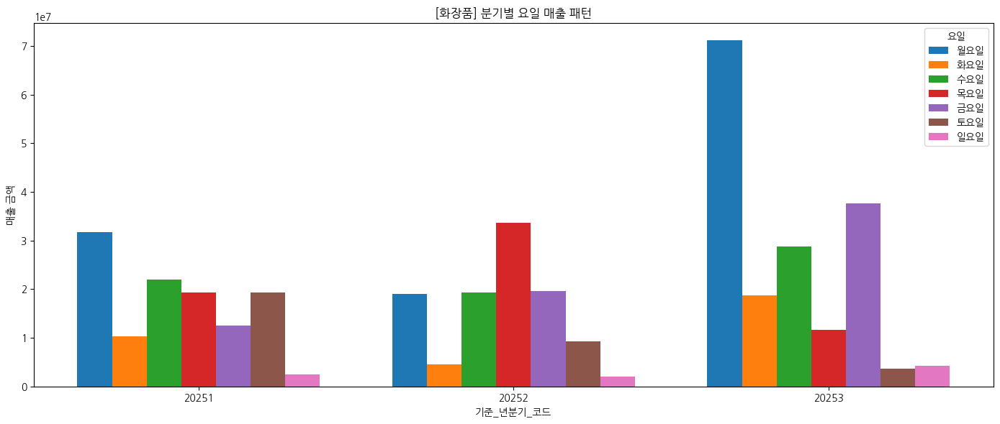

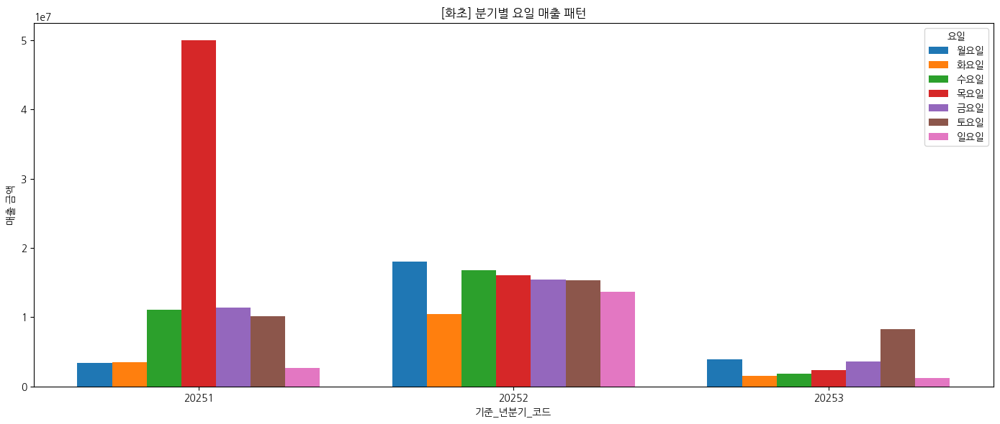

In [37]:
industries = sorted(weekday_agg["서비스_업종_코드_명"].unique())

for ind in industries:
    plot_weekday_sales_by_industry(ind)


# 분기별/상권별 주말 vs 주중 매출 건수(업종별 나눠서)

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weekday_type_cols = [
    "주중_매출_건수",
    "주말_매출_건수",
]

need_cols = ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"] + weekday_type_cols
missing = [c for c in need_cols if c not in df.columns]
assert not missing, f"필요 컬럼 누락: {missing}"

tmp = df.copy()
tmp["기준_년분기_코드"] = pd.to_numeric(tmp["기준_년분기_코드"], errors="coerce")
for c in weekday_type_cols:
    tmp[c] = pd.to_numeric(tmp[c], errors="coerce")


In [39]:
weekday_type_agg = (
    tmp.groupby(
        ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"],
        as_index=False
    )[weekday_type_cols]
    .sum()
)


In [40]:
def plot_weekday_vs_weekend_by_industry(industry_name):
    sub = weekday_type_agg[
        weekday_type_agg["서비스_업종_코드_명"] == industry_name
    ].copy()

    if sub.empty:
        print(f"⚠️ 데이터 없음: {industry_name}")
        return

    # 상권 합산 → 분기별 주중/주말 비교
    plot_df = (
        sub.groupby("기준_년분기_코드")[weekday_type_cols]
           .sum()
           .sort_index()
    )

    quarters = plot_df.index.astype(int).astype(str)
    x = np.arange(len(quarters))
    bar_width = 0.35

    plt.figure(figsize=(12, 6))

    plt.bar(
        x - bar_width/2,
        plot_df["주중_매출_건수"],
        width=bar_width,
        label="주중"
    )
    plt.bar(
        x + bar_width/2,
        plot_df["주말_매출_건수"],
        width=bar_width,
        label="주말"
    )

    plt.xticks(x, quarters)
    plt.xlabel("기준_년분기_코드")
    plt.ylabel("매출 건수")
    plt.title(f"[{industry_name}] 분기별 주중 vs 주말 매출 건수")
    plt.legend()
    plt.tight_layout()
    plt.show()


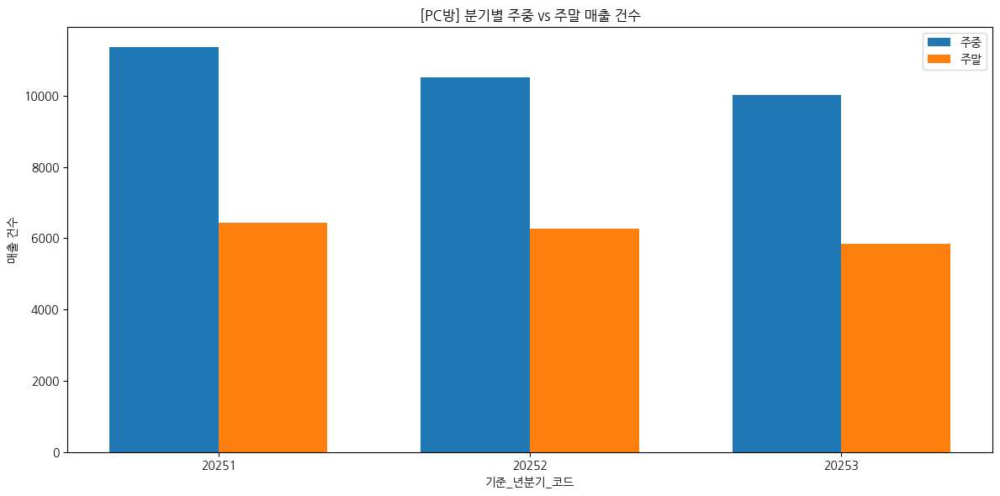

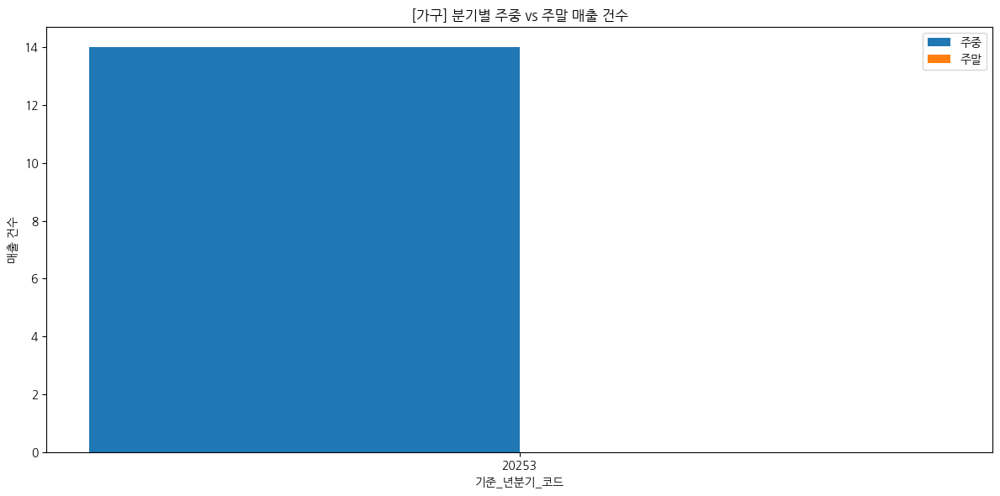

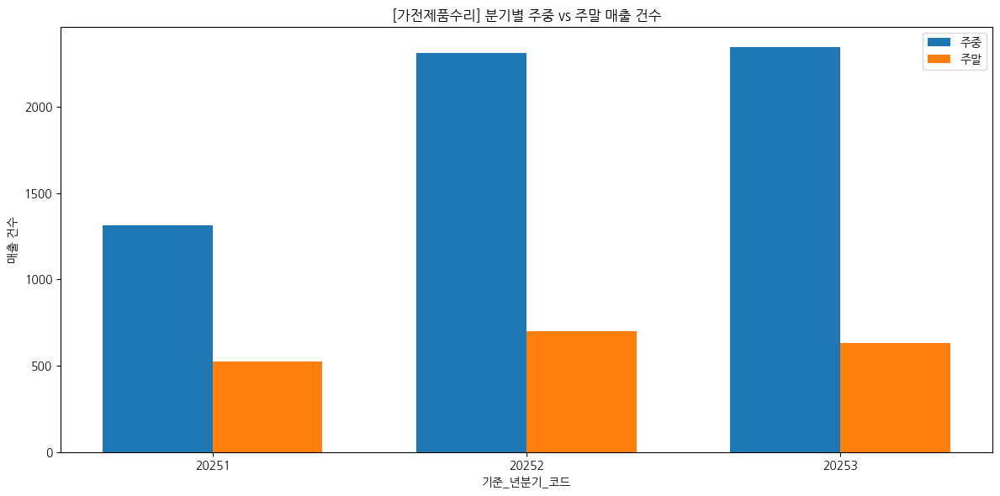

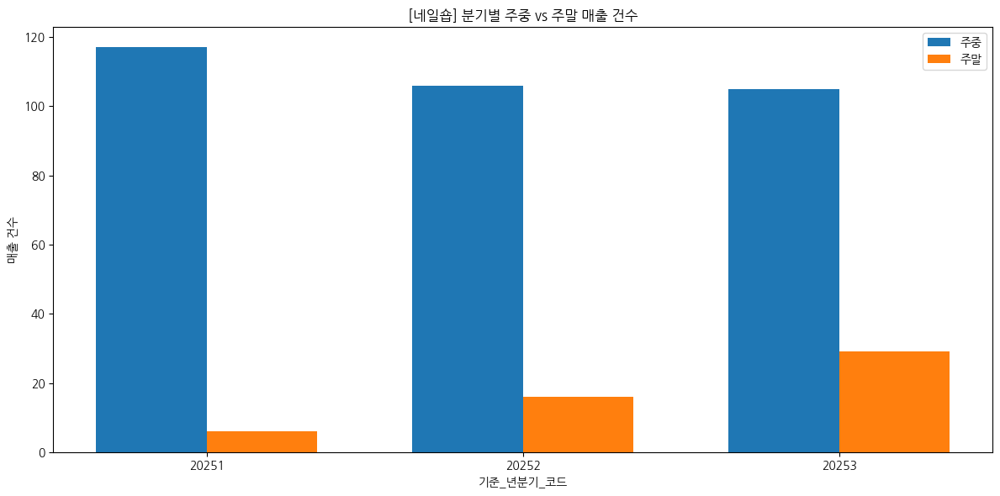

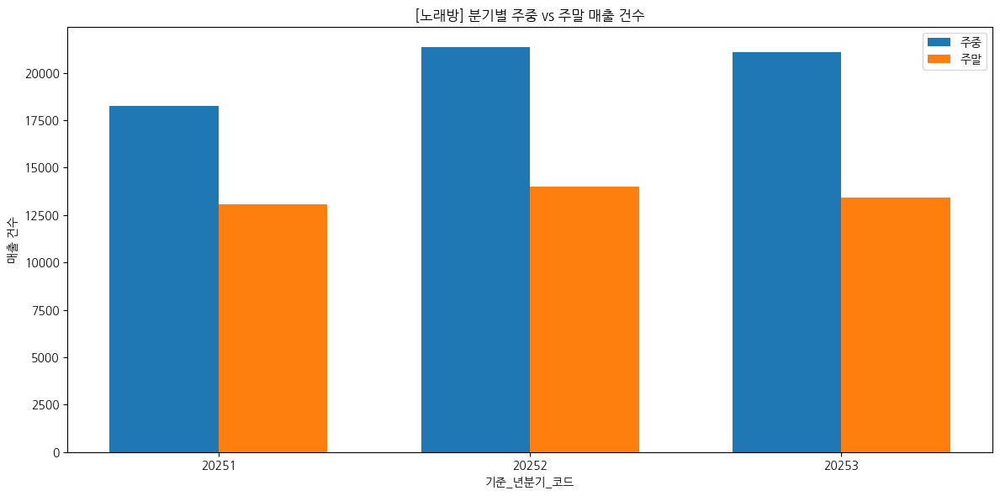

...

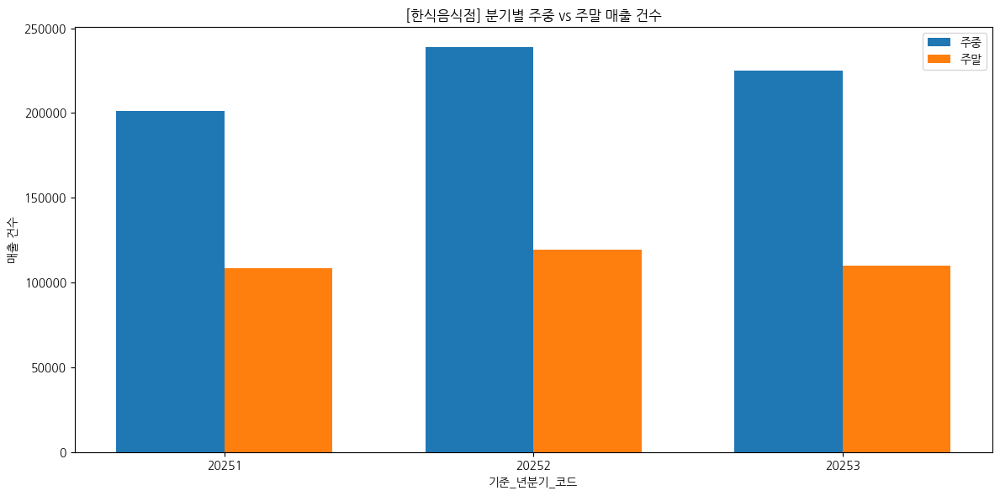

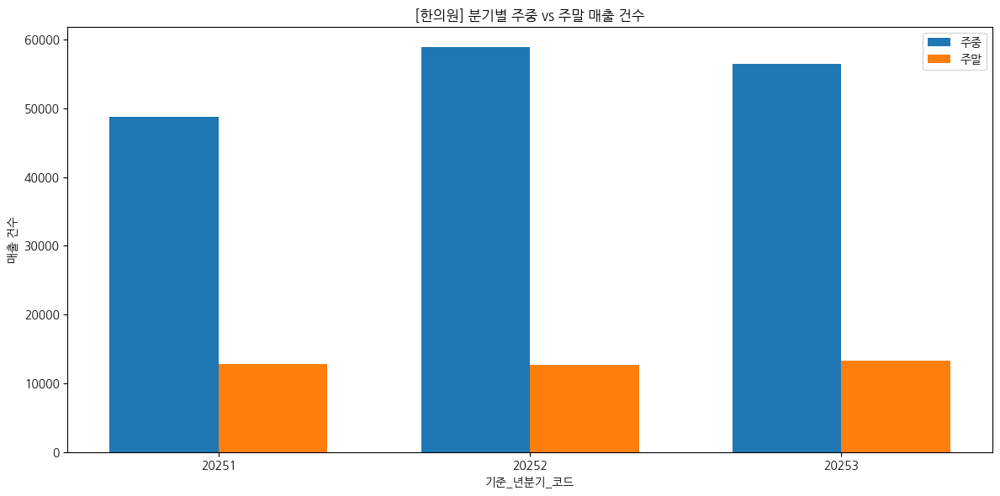

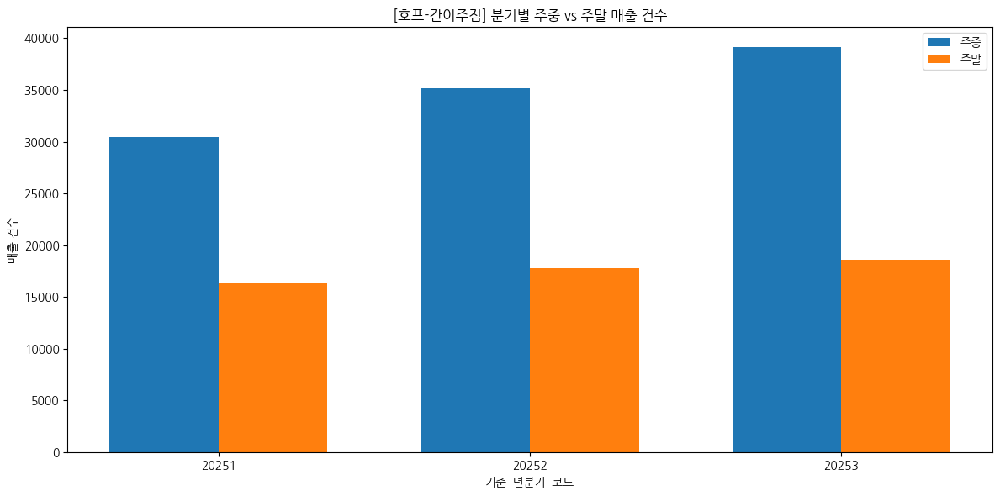

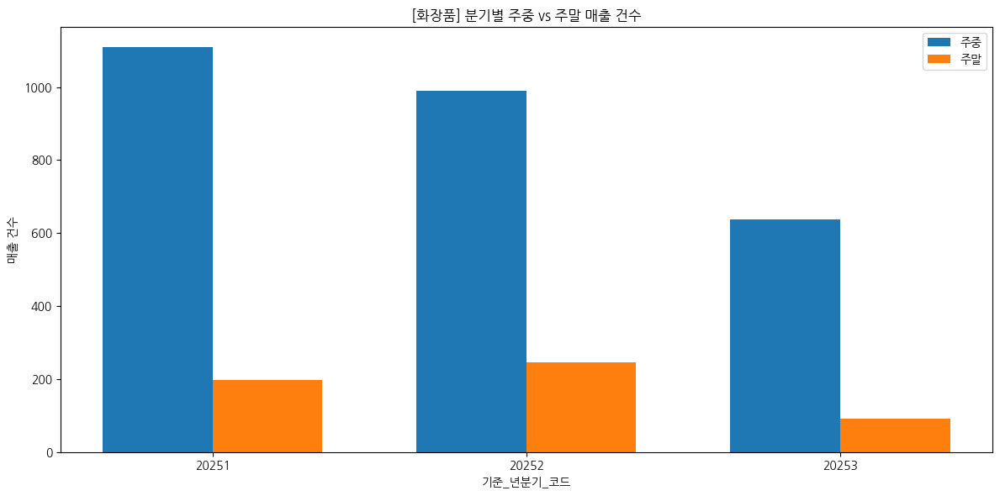

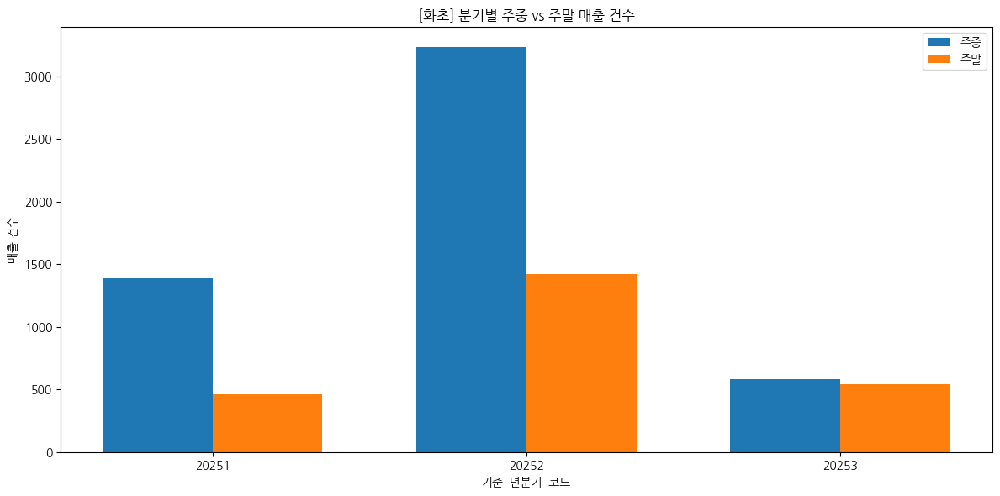

In [41]:
industries = sorted(weekday_type_agg["서비스_업종_코드_명"].unique())

for ind in industries:
    plot_weekday_vs_weekend_by_industry(ind)


## 주중/주말 평균내서 차이 확인

In [42]:
weekday_type_avg = weekday_type_agg.copy()

weekday_type_avg["주중_일평균_매출_건수"] = (
    weekday_type_avg["주중_매출_건수"] / 5
)

weekday_type_avg["주말_일평균_매출_건수"] = (
    weekday_type_avg["주말_매출_건수"] / 2
)


In [43]:
import numpy as np
import matplotlib.pyplot as plt

def plot_weekday_vs_weekend_avg_by_industry(industry_name):
    sub = weekday_type_avg[
        weekday_type_avg["서비스_업종_코드_명"] == industry_name
    ].copy()

    if sub.empty:
        print(f"⚠️ 데이터 없음: {industry_name}")
        return

    # 상권 합산 → 분기별 일평균 비교
    plot_df = (
        sub.groupby("기준_년분기_코드")[
            ["주중_일평균_매출_건수", "주말_일평균_매출_건수"]
        ]
        .sum()
        .sort_index()
    )

    quarters = plot_df.index.astype(int).astype(str)
    x = np.arange(len(quarters))
    bar_width = 0.35

    plt.figure(figsize=(12, 6))

    plt.bar(
        x - bar_width / 2,
        plot_df["주중_일평균_매출_건수"],
        width=bar_width,
        label="주중 (일평균)"
    )
    plt.bar(
        x + bar_width / 2,
        plot_df["주말_일평균_매출_건수"],
        width=bar_width,
        label="주말 (일평균)"
    )

    plt.xticks(x, quarters)
    plt.xlabel("기준_년분기_코드")
    plt.ylabel("일평균 매출 건수")
    plt.title(f"[{industry_name}] 분기별 주중 vs 주말 일평균 매출 건수")
    plt.legend()
    plt.tight_layout()
    plt.show()


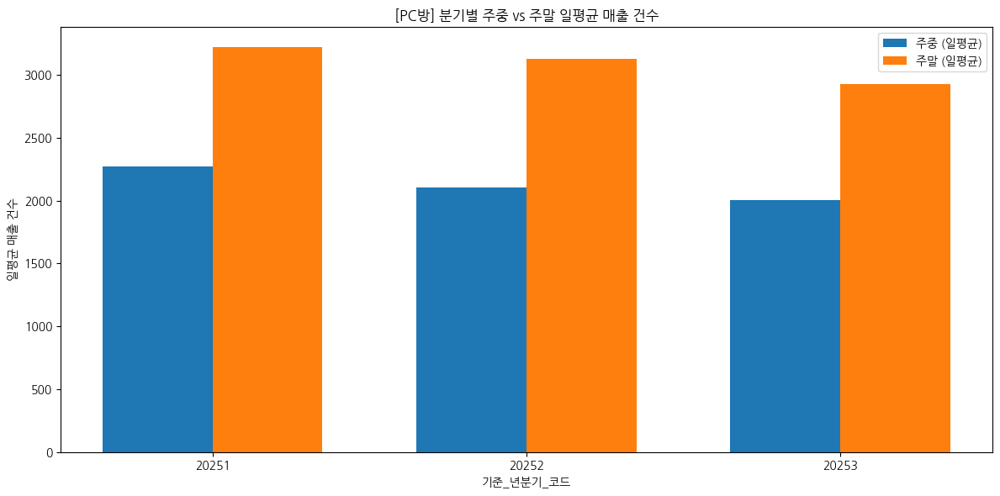

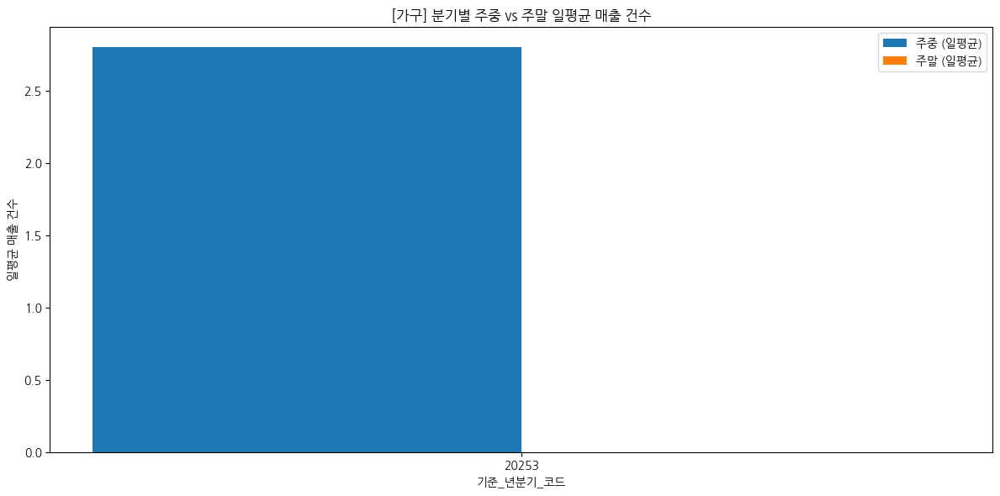

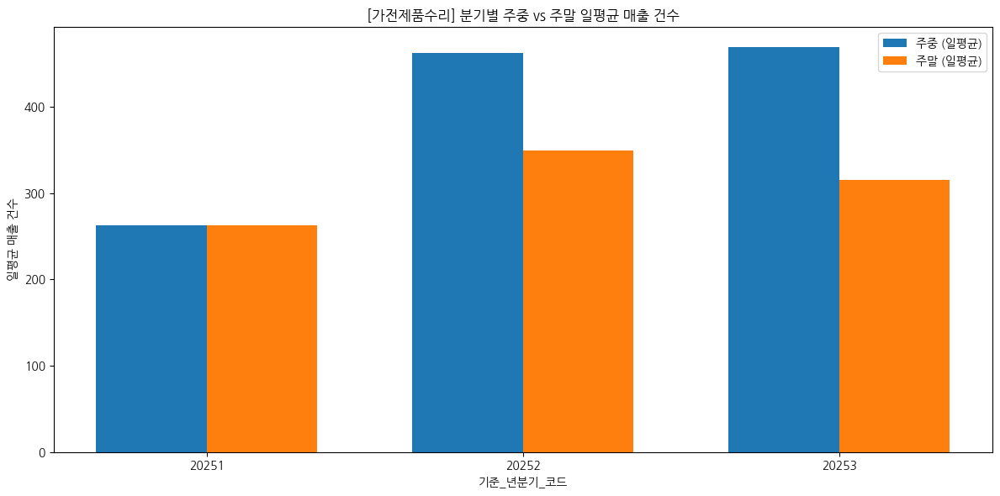

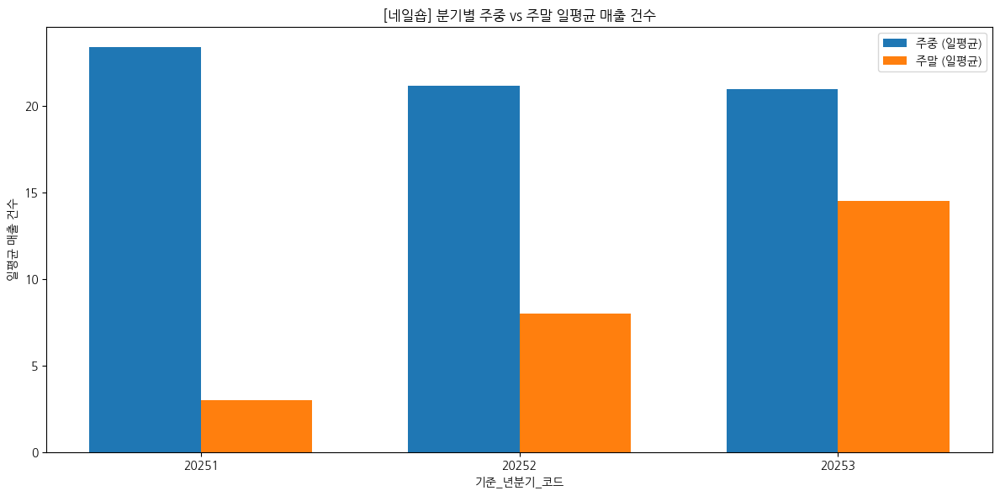

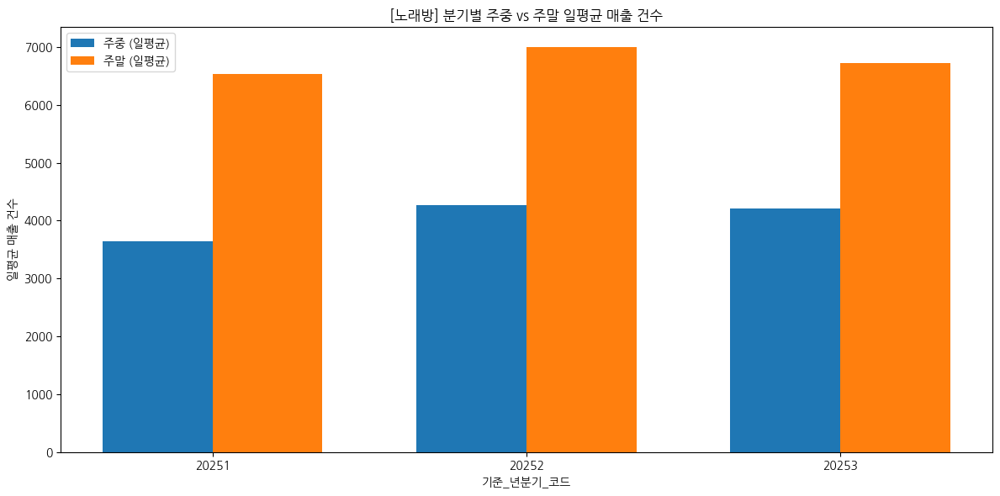

...

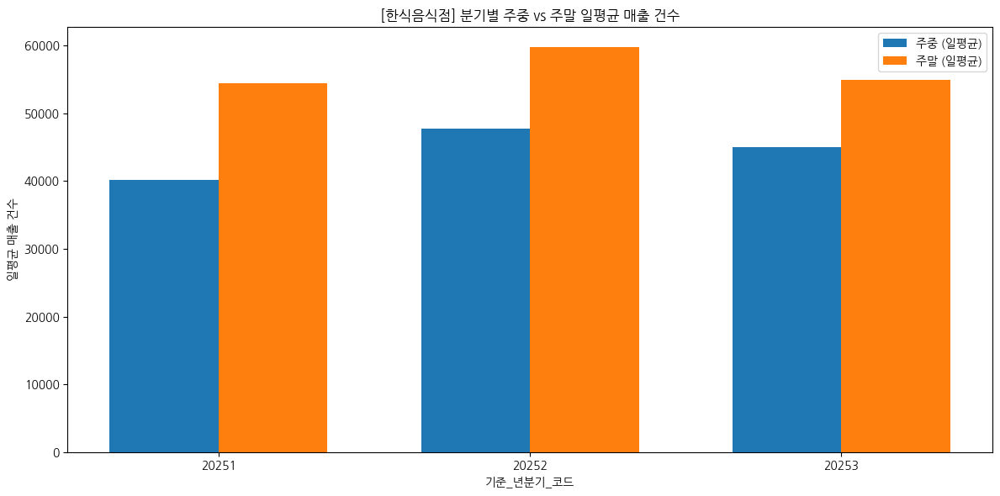

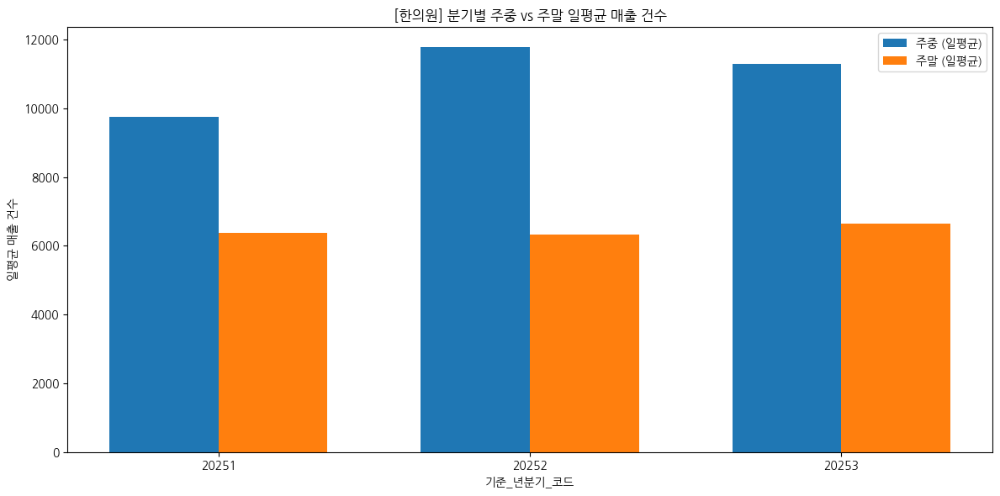

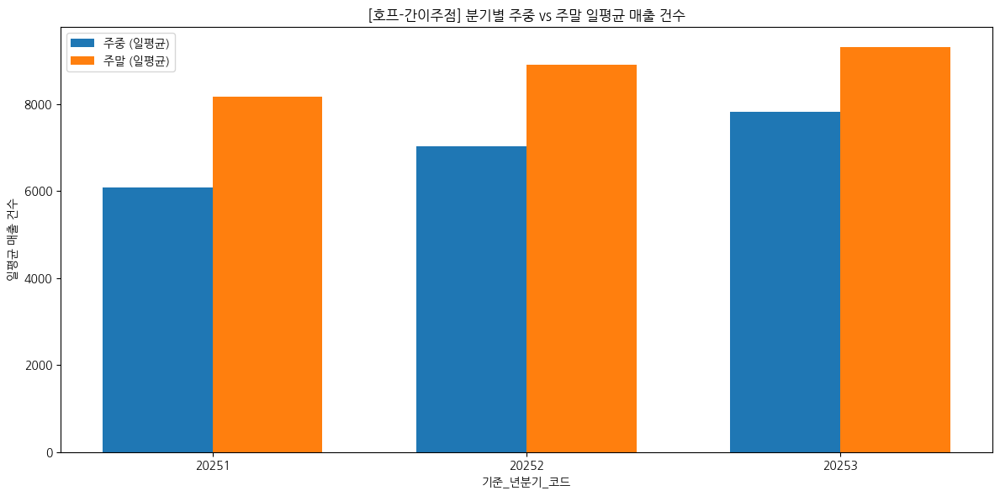

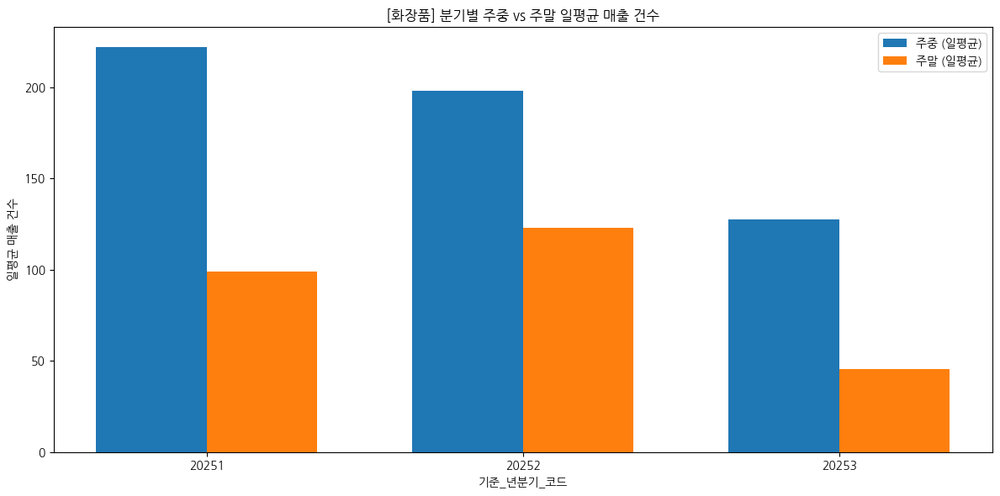

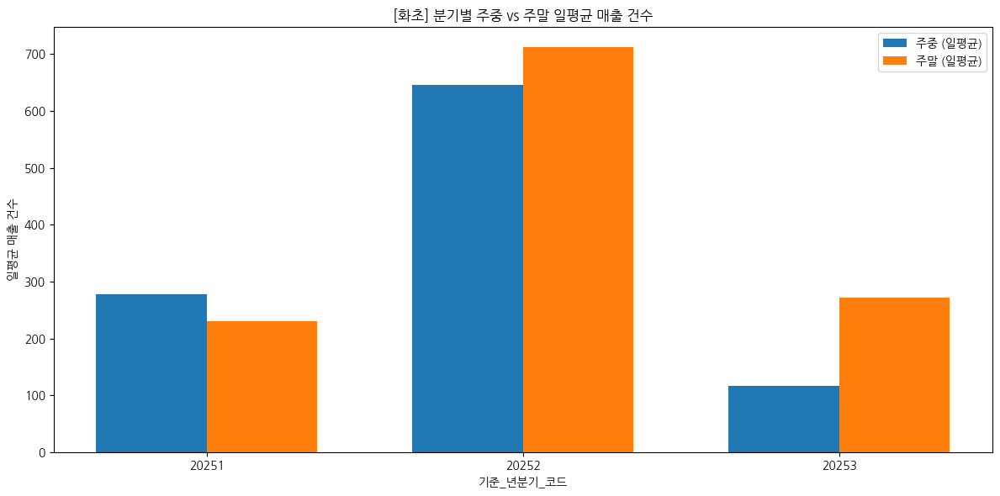

In [44]:
industries = sorted(weekday_type_avg["서비스_업종_코드_명"].unique())

for ind in industries:
    plot_weekday_vs_weekend_avg_by_industry(ind)


# 분기별/상권별 남녀 매출 건수(업종별로) - 이 그래프랑 남녀 매출 금액 보면 업종별 남녀 소비력 알 수 있음

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

gender_count_cols = [
    "남성_매출_건수",
    "여성_매출_건수",
]

need_cols = ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"] + gender_count_cols
missing = [c for c in need_cols if c not in df.columns]
assert not missing, f"필요 컬럼 누락: {missing}"

tmp = df.copy()
tmp["기준_년분기_코드"] = pd.to_numeric(tmp["기준_년분기_코드"], errors="coerce")
for c in gender_count_cols:
    tmp[c] = pd.to_numeric(tmp[c], errors="coerce")


In [46]:
gender_count_agg = (
    tmp.groupby(
        ["기준_년분기_코드", "서비스_업종_코드_명", "상권_코드_명"],
        as_index=False
    )[gender_count_cols]
    .sum()
)


In [47]:
def plot_gender_count_by_industry(industry_name):
    sub = gender_count_agg[
        gender_count_agg["서비스_업종_코드_명"] == industry_name
    ].copy()

    if sub.empty:
        print(f"⚠️ 데이터 없음: {industry_name}")
        return

    # 상권 합산 → 분기별 남/여 건수
    plot_df = (
        sub.groupby("기준_년분기_코드")[gender_count_cols]
           .sum()
           .sort_index()
    )

    quarters = plot_df.index.astype(int).astype(str)
    x = np.arange(len(quarters))
    bar_width = 0.35

    plt.figure(figsize=(12, 6))

    plt.bar(
        x - bar_width / 2,
        plot_df["남성_매출_건수"],
        width=bar_width,
        label="남성"
    )
    plt.bar(
        x + bar_width / 2,
        plot_df["여성_매출_건수"],
        width=bar_width,
        label="여성"
    )

    plt.xticks(x, quarters)
    plt.xlabel("기준_년분기_코드")
    plt.ylabel("매출 건수")
    plt.title(f"[{industry_name}] 분기별 남녀 매출 건수")
    plt.legend()
    plt.tight_layout()
    plt.show()


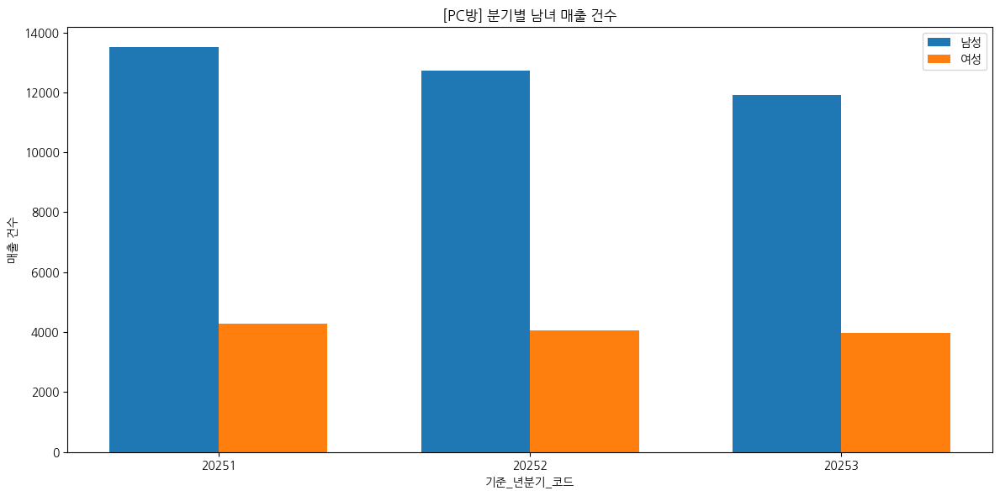

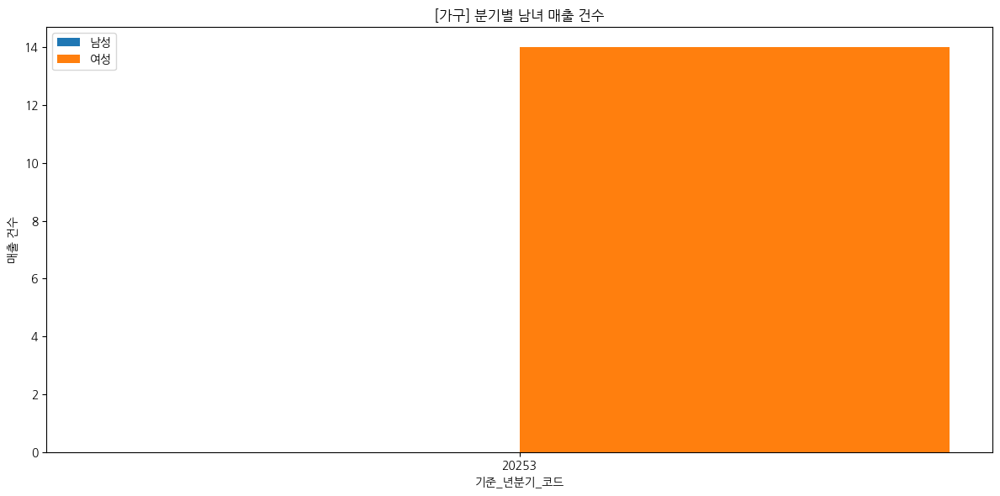

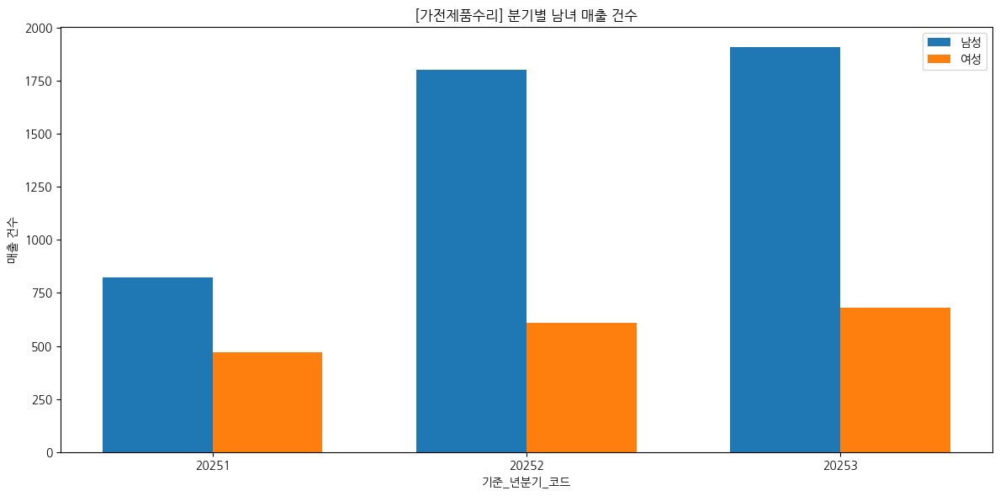

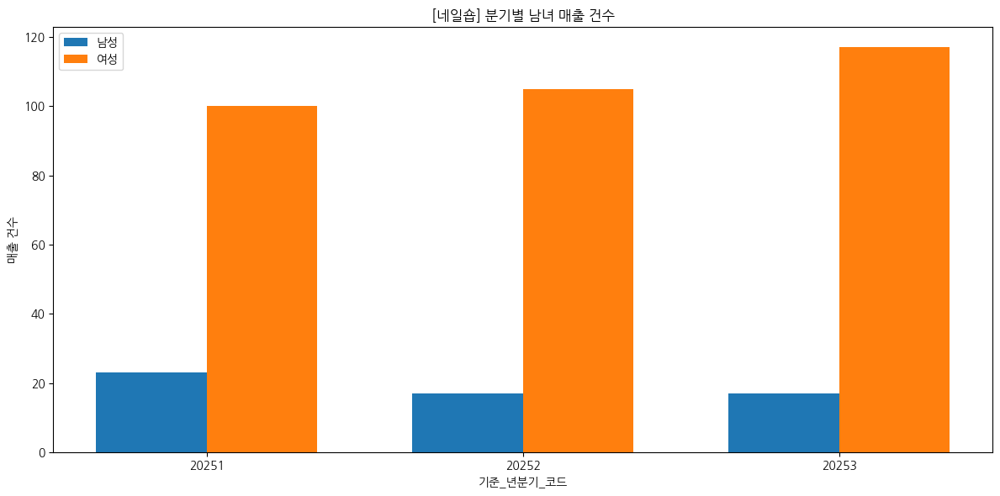

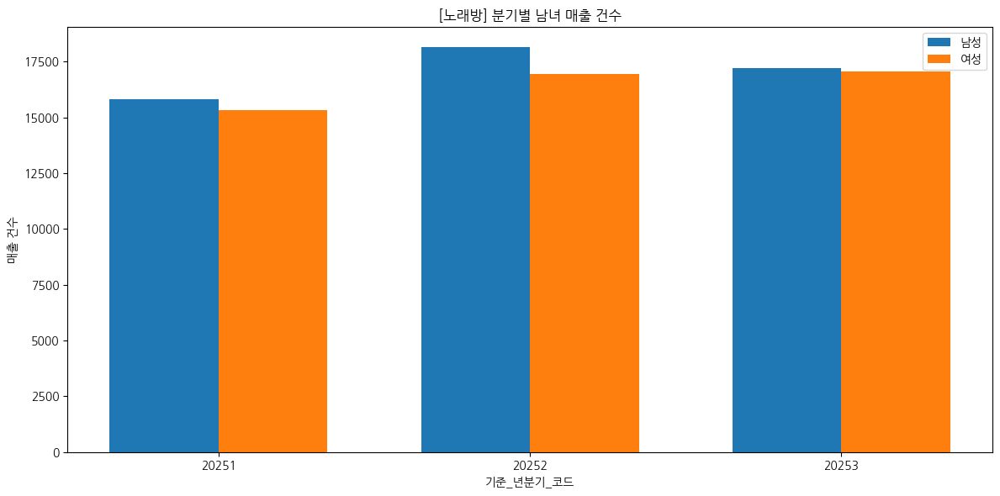

...

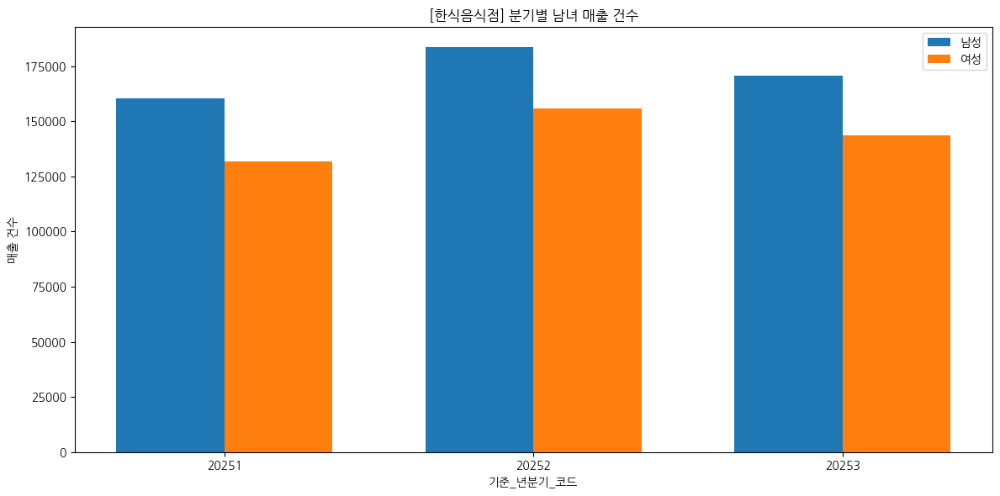

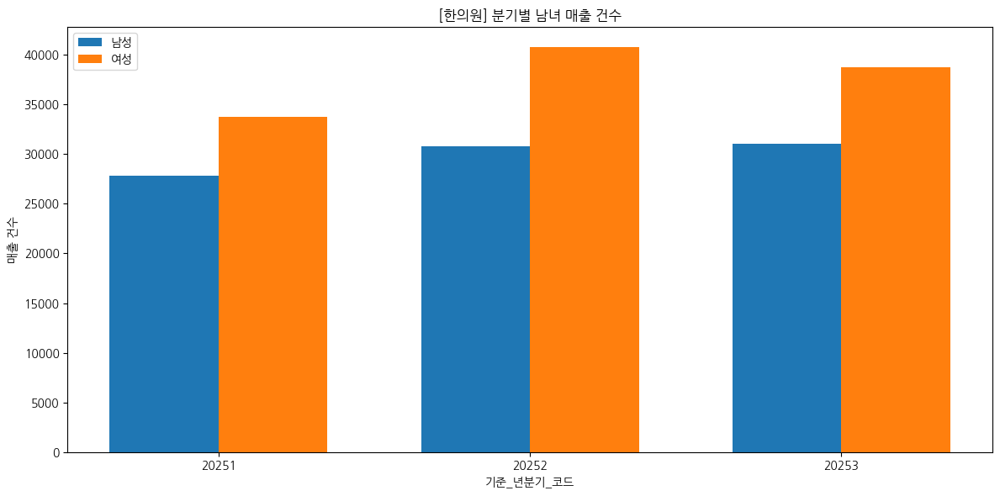

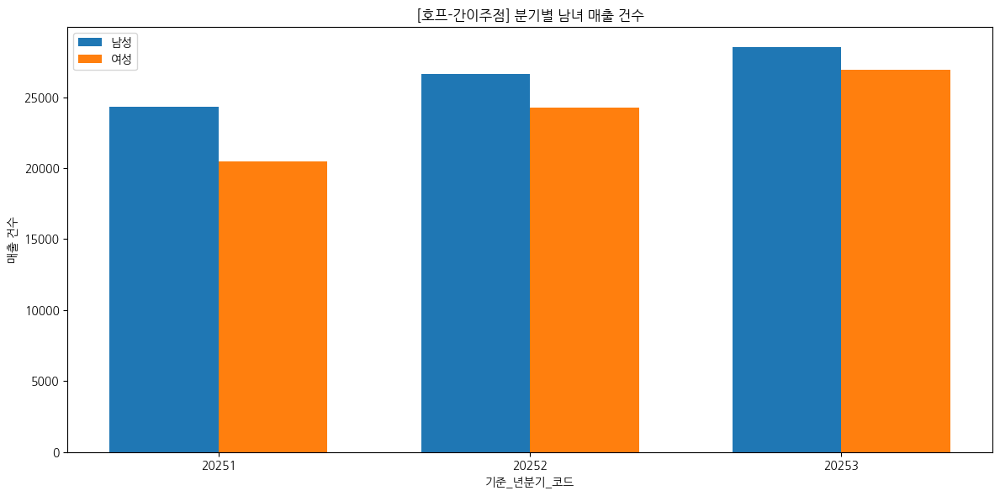

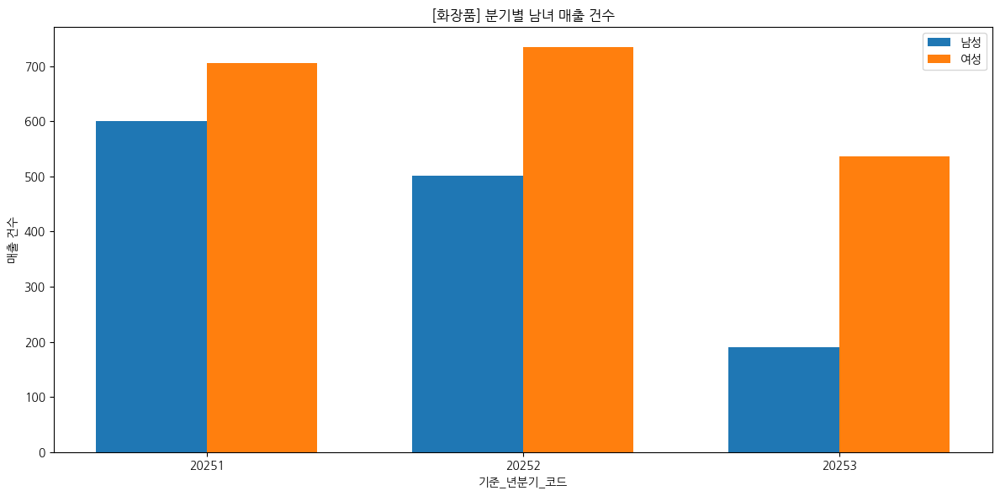

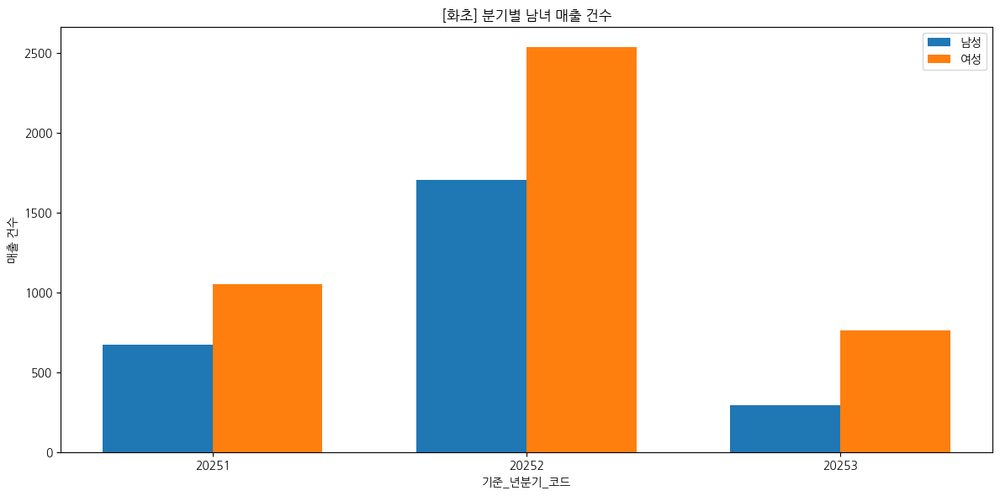

In [48]:
industries = sorted(gender_count_agg["서비스_업종_코드_명"].unique())

for ind in industries:
    plot_gender_count_by_industry(ind)
